# Partie 1 : Chaîne de traitement complète sur un dataset « Data »
## *International Bestselling Books — Market Trends* (Kaggle)

**Chaîne suivie :** Data → EDA → Prétraitement → Transformation → ML → Évaluation → Déploiement.

**Point de départ.** Ce notebook reprend le notebook Kaggle *« International Bestselling Books EDA »*
(onglet *Code* du dataset ; auteur et lien : `Laksh Lukhi`, `https://www.kaggle.com/code/lukhilaksh/international-bestselling-books-eda`). Ce notebook d'origine charge
les données, remplit les valeurs manquantes puis trace 15 graphiques. Il ne contient **aucun commentaire,
aucun modèle de Machine Learning ni aucune évaluation**.

**Ce que nous avons fait :**
- **repris** tout son code, dans l'ordre de la chaîne demandée (son remplissage des valeurs manquantes est
  déplacé de l'EDA vers la partie Prétraitement) ;
- **expliqué et commenté** chaque étape, chaque résultat et chaque graphique ;
- **vérifié** chaque graphique : plusieurs ne montrent rien d'autre qu'un effet de construction des données,
  ou conduisent à une conclusion fausse. Ils sont signalés par **Correction**, expliqués, puis
  remplacés par une version correcte ;
- **ajouté** les étapes absentes : analyses complémentaires, prétraitement justifié, transformation,
  modélisation, évaluation et déploiement.

## 1. Data

### 1.1 Source et contenu
Le dataset recense, pour plusieurs pays et pour chaque mois, les **10 livres les plus vendus** (classement
*top 10*), de juin 2013 à décembre 2022. Les titres sont traduits en anglais, ce qui permet de reconnaître le
même livre d'un pays à l'autre.

**Point essentiel :** le dataset ne contient **aucun chiffre de ventes**, seulement le **rang** (1 à 10) dans
le classement. Toute notion de « succès » devra donc être construite à partir des rangs et des apparitions.

### 1.2 Importation des bibliothèques (code d'origine)
- `numpy`, `pandas` : calcul et manipulation de tableaux de données ;
- `matplotlib`, `seaborn` : graphiques ;
- `warnings.filterwarnings('ignore')` masque les avertissements. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### 1.3 Chargement du fichier (code d'origine, chemin adapté)
Le chemin d'origine `/kaggle/input/...` n'existe que sur les serveurs de Kaggle. Nous lisons le fichier CSV
placé à côté du notebook.

In [2]:
df = pd.read_csv('international_bestsellers_dataset.csv')
df_raw = df.copy()      # ajout : copie brute intacte, pour comparer avant / après nettoyage

### 1.4 Premier aperçu (code d'origine)
`head()` et `tail()` affichent les 5 premières et dernières lignes, `shape` les dimensions (lignes, colonnes),
`columns` les noms des colonnes, `dtypes` et `info()` leurs types et le nombre de valeurs non nulles.

In [3]:
df.head()

,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
0,2022-12-01,France,1,The Wizard of the Kremlin,Giuliano da Empoli,Italy,m,2022-02Bulgaria591,Éditions Gallimard,France
1,2022-12-01,Germany,1,Facial Expressions,Sebastian Fitzek,Germany,m,2022-02Bulgaria601,Droemer Knaur,Germany
2,2022-12-01,Italy,1,The House of Lights,Donato Carrisi,Italy,m,2022-02Bulgaria611,Longanesi,Italy
3,2022-12-01,Spain,1,Waiting for the Deluge,Dolores Redondo,Spain,w,2022-02Bulgaria621,Destino,Spain
4,2022-12-01,Egypt,1,Orfanelli Hall,Achraf El Achmawi,Egypt,m,2022-02Bulgaria631,The Egyptian Lebanese House,Egypt


In [4]:
df.tail()

,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
7904,2013-06-01,Germany,10,The Golden Shore,Iny Lorentz,Germany,m; w,2013-06Germany10,Droemer Knaur,Germany
7905,2013-06-01,Italy,10,I Watch You,Irene Cao,Italy,w,2013-06Italy10,Rizzoli,Italy
7906,2013-06-01,South Korea,10,The Art of Thinking Clearly,Rolf Dobelli,Switzerland,m,2013-06South Korea10,Hanser,Germany
7907,2013-06-01,Spain,10,The Barefoot Queen,Ildefonso Falcones,Spain,m,2013-06Spain10,Grijalbo,Spain
7908,2013-06-01,United States,10,Best Kept Secret,Jeffrey Archer,United Kingdom,m,2013-06United States10,Macmillan,United Kingdom


In [5]:
df.shape

(7909, 10)

In [6]:
df.columns

Index(['date', 'country', 'rank', 'title', 'author', 'nationality', 'gender',
       'entry_id', 'publisher', 'publication_country'],
      dtype='object')

In [7]:
df.dtypes

date                   object
country                object
rank                    int64
title                  object
author                 object
nationality            object
gender                 object
entry_id               object
publisher              object
publication_country    object
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7909 entries, 0 to 7908
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   date                 7909 non-null   object
 1   country              7909 non-null   object
 2   rank                 7909 non-null   int64 
 3   title                7909 non-null   object
 4   author               7909 non-null   object
 5   nationality          7899 non-null   object
 6   gender               7899 non-null   object
 7   entry_id             7909 non-null   object
 8   publisher            7907 non-null   object
 9   publication_country  7909 non-null   object
dtypes: int64(1), object(9)
memory usage: 618.0+ KB


**Lecture.** 7 909 lignes et 10 colonnes. Une ligne correspond à **un livre classé dans le top 10 d'un pays,
pour un mois donné**. Une seule colonne est numérique (`rank`) : toutes les autres sont du texte (`object`),
y compris `date`, qu'il faudra convertir en vraie date pour faire des analyses temporelles.

### 1.5 Dictionnaire des données (ajout)

| Colonne | Signification | Nature | Remarque |
|---|---|---|---|
| `date` | mois du classement (toujours le 1er du mois) | temporelle | à convertir en date |
| `country` | pays du classement | catégorielle (45 pays) | |
| `rank` | position dans le top 10 (1 = meilleure vente) | **ordinale** | 1 est mieux que 10, mais l'écart entre deux rangs n'est pas une quantité mesurable |
| `title` | titre traduit en anglais | texte (3 754 titres) | deux livres différents peuvent avoir le même titre |
| `author` | auteur(s) | catégorielle (1 850 auteurs) | `[Various]` = ouvrage collectif |
| `nationality` | nationalité de l'auteur | catégorielle | plusieurs valeurs séparées par `;` s'il y a plusieurs auteurs |
| `gender` | genre de l'auteur : `m` homme, `w` femme, `n` non précisé | catégorielle | idem, valeurs multiples pour les co-auteurs |
| `entry_id` | identifiant de la ligne | identifiant | doit être unique ; aucune information utile pour l'analyse |
| `publisher` | éditeur | catégorielle (750 éditeurs) | |
| `publication_country` | pays de l'éditeur | catégorielle (52 pays) | |

### 1.6 Vérification de la structure (ajout)
On vérifie que les données ont bien la structure annoncée : un classement de 10 livres par pays et par mois.

In [9]:
# 1) entry_id est-il bien un identifiant unique ?
print("entry_id unique :", df["entry_id"].is_unique)

# 2) Chaque classement (mois, pays) contient-il 10 livres ?
taille_listes = df.groupby(["date", "country"]).size()
print("Nombre de classements (mois × pays) :", len(taille_listes))
print("Classements qui n'ont pas 10 lignes :")
print(taille_listes[taille_listes != 10])

# 3) Chaque rang apparaît-il une seule fois par classement ?
print("Rangs en double dans un même classement :", df.duplicated(["date", "country", "rank"]).sum())

# 4) Période couverte
print("Période :", df["date"].min(), "->", df["date"].max())

entry_id unique : True
Nombre de classements (mois × pays) : 791
Classements qui n'ont pas 10 lignes :
date        country
2016-09-01  Spain      9
dtype: int64
Rangs en double dans un même classement : 0
Période : 2013-06-01 -> 2022-12-01


**Lecture.**
- `entry_id` est unique : chaque ligne est une entrée distincte.
- Il y a 791 classements de 10 livres. **Un seul est incomplet** (Espagne, septembre 2016 : 9 livres) ;
  une ligne manquante sur 7 909 n'a pas d'effet sur l'analyse, on le garde.
- Aucun rang n'apparaît deux fois dans un même classement : la structure « top 10 » est cohérente.

In [ ]:
couverture = (df.groupby("country")
               .agg(nb_mois=("date", "nunique"), nb_lignes=("rank", "size"),
                    premier=("date", "min"), dernier=("date", "max"))
               .sort_values("nb_mois", ascending=False))
couverture.head(12)

,nb_mois,nb_lignes,premier,dernier
country,,,,
Germany,114,1140,2013-06-01,2022-12-01
Spain,114,1139,2013-06-01,2022-12-01
United States,114,1140,2013-06-01,2022-12-01
Italy,114,1140,2013-06-01,2022-12-01
France,113,1130,2013-06-01,2022-12-01
Brazil,10,100,2014-03-01,2022-04-01
Greece,9,90,2014-05-01,2022-07-01
Poland,9,90,2014-06-01,2022-08-01
Ireland,9,90,2014-02-01,2022-11-01


In [11]:
grands = couverture.index[couverture["nb_mois"] > 100].tolist()     # pays suivis chaque mois
print("Pays suivis chaque mois :", grands)
print(f"Part des lignes provenant de ces pays : {df['country'].isin(grands).mean():.1%}")
print("Nombre de classements des 40 autres pays :",
      couverture.loc[~couverture.index.isin(grands), "nb_mois"].describe()[["min", "max"]].to_dict())

Pays suivis chaque mois : ['Germany', 'Spain', 'United States', 'Italy', 'France']
Part des lignes provenant de ces pays : 71.9%
Nombre de classements des 40 autres pays : {'min': 1.0, 'max': 10.0}


**Lecture : une couverture très déséquilibrée.** Cinq pays (États-Unis, Allemagne, Italie, Espagne, France)
sont suivis **chaque mois** pendant presque 10 ans. Ils représentent 72 % des lignes. Les 40 autres pays
n'ont que 1 à 10 classements, à peu près un par an.

**Conséquences pour la suite :**
- toute statistique globale est dominée par ces 5 pays ;
- un livre a mécaniquement plus de chances d'apparaître plusieurs fois s'il est vendu dans l'un de ces pays ;
- on ne pourra pas comparer naïvement les pays entre eux, ni les années entre elles, car la liste des
  « petits » pays présents change d'une année à l'autre.

C'est un **biais d'échantillonnage**. Il sera rappelé à chaque fois qu'il influence un résultat.

## 2. EDA — Analyse exploratoire des données

**Objectif.** Comprendre les données avant de les modifier : qualité (valeurs manquantes, doublons,
incohérences), distributions, relations entre variables. Chaque constat de l'EDA justifie un choix des
étapes suivantes (prétraitement, transformation, choix de la cible du modèle).

### 2.1 Valeurs manquantes (code d'origine)

In [12]:
df.isnull().sum()

date                    0
country                 0
rank                    0
title                   0
author                  0
nationality            10
gender                 10
entry_id                0
publisher               2
publication_country     0
dtype: int64

Le notebook d'origine remplit immédiatement ces valeurs par la valeur la plus fréquente (le *mode*). Avant de
décider quoi en faire, regardons **quelles** lignes sont concernées (ajout) :

In [13]:
df[df[["nationality", "gender", "publisher"]].isnull().any(axis=1)]

,date,country,rank,title,author,nationality,gender,entry_id,publisher,publication_country
61,2022-04-01,Singapore,1,Fine Print,Lauren Asher,NaN,w,2022-02Bulgaria81,KDP,United States
473,2017-04-01,Italy,1,Traveling In Yellow,[Various],NaN,NaN,2017-04Italy1,Sellerio Editore,Italy
1255,2017-05-01,Italy,2,Traveling In Yellow,[Various],NaN,NaN,2017-05Italy2,Sellerio Editore,Italy
1456,2014-12-01,Taiwan,2,Not The Other Party,Cheer,NaN,NaN,2014-12Taiwan2,Life Publishing Ltd,China
1643,2022-04-01,Singapore,3,Terms and Conditions,Lauren Asher,NaN,w,2022-02Bulgaria83,Piatkus,United Kingdom
3629,2017-05-01,Japan,5,Material Collector's World Tour Book 2,Kinoko Tetsu,Japan,NaN,2017-05Japan5,NaN,Japan
3694,2016-08-01,Turkey,5,Coffee Scented Stories,[Various],NaN,NaN,2016-08Turkey5,Yakamoz Yayınları,Turkey
3713,2016-05-01,Japan,5,VRMMO Symbol 9,Shiina HowaHowa,NaN,NaN,2016-05Japan5,AlphaPolis,Japan
4524,2016-02-01,Netherlands,6,Once Again The Course Dealing With Disappointm...,Herman Hermits,NaN,NaN,2016-02Netherlands6,Thomas Rap,Netherlands
5211,2017-05-01,Japan,7,Fairy Tale: Chronicle Air 14,Haniwa Star Man,Japan,NaN,2017-05Japan7,NaN,Japan


In [14]:
print("Mode de nationality :", df["nationality"].mode()[0])
print("Mode de gender      :", df["gender"].mode()[0])
print("Mode de publisher   :", df["publisher"].mode()[0])

Mode de nationality : United States
Mode de gender      : m
Mode de publisher   : Doubleday


**Lecture.** Seules 12 lignes sur 7 909 (0,15 %) ont une valeur manquante. Ce ne sont pas des erreurs au
hasard :
- 4 lignes sont des **ouvrages collectifs** (`[Various]`) : ils n'ont ni une nationalité ni un genre uniques ;
- les autres sont surtout des **auteurs japonais ou asiatiques** peu connus (light novels).

**Correction.** Le remplissage par le mode, fait dans le notebook d'origine, est ici **incorrect** :
il donnerait la nationalité `United States`, le genre `m` et l'éditeur `Doubleday` (un éditeur américain) à
des livres japonais publiés au Japon, et un genre masculin à des recueils collectifs. Ces valeurs inventées
seraient fausses. Le traitement retenu est expliqué dans la partie Prétraitement : une catégorie explicite
« inconnu ».

### 2.2 Doublons (code d'origine, puis vérification complémentaire)

In [15]:
df.duplicated().sum()

np.int64(0)

`duplicated()` cherche des lignes **entièrement identiques**. Il n'y en a aucune, ce qui est logique puisque
`entry_id` est unique. Mais ce test ne détecte pas les doublons qui ont un sens « métier » (ajout) :

In [16]:
# même livre (titre + auteur) deux fois dans le même classement
doublons_liste = df[df.duplicated(["date", "country", "title", "author"], keep=False)]
print("Lignes concernées :", len(doublons_liste))
doublons_liste.sort_values(["date", "country"])[["date", "country", "rank", "title", "author", "publisher"]]

Lignes concernées : 16


,date,country,rank,title,author,publisher
637,2015-04-01,Italy,1,Moments Of Negligible Happiness,Francesco Piccolo,Einaudi
2219,2015-04-01,Italy,3,Moments Of Negligible Happiness,Francesco Piccolo,Einaudi
5978,2017-08-01,China,8,Ordinary World,Lu Yao,Beijing October Literature and Arts Press
7560,2017-08-01,China,10,Ordinary World,Lu Yao,Beijing October Literature and Arts Press
1165,2018-06-01,Mexico,2,The Little Prince,Antoine de Saint-Exupéry,Éditions Gallimard
4329,2018-06-01,Mexico,6,The Little Prince,Antoine de Saint-Exupéry,Éditions Gallimard
1939,2018-08-01,China,3,Ordinary World,Lu Yao,Beijing October Literature and Arts Press
4312,2018-08-01,China,6,Ordinary World,Lu Yao,Beijing October Literature and Arts Press
4169,2020-05-01,Philippines,6,P.S. I Still Love You,Jenny Han,Simon & Schuster
4960,2020-05-01,Philippines,7,P.S. I Still Love You,Jenny Han,Simon & Schuster


In [17]:
# un même titre peut-il désigner des livres différents ?
auteurs_par_titre = df.groupby("title")["author"].nunique()
print("Titres partagés par plusieurs auteurs :", (auteurs_par_titre > 1).sum())
df[df["title"].isin(["Home", "Love", "Invisible", "Bullet Train"])].drop_duplicates(["title", "author"])[["title", "author", "nationality"]]

Titres partagés par plusieurs auteurs : 45


,title,author,nationality
1709,Home,Judith Hermann,Germany
1752,Love,Roddy Doyle,Ireland
3863,Invisible,James Patterson; David Ellis,United States; United States
4265,Home,Harlan Coben,United States
5561,Invisible,Eloy Moreno,Spain
5653,Love,Catena Fiorello Galeano,Italy
6465,Bullet Train,Kōtarō Isaka,Japan
7241,Bullet Train,Kotara lsaka,Japan


**Lecture.**
- **8 lignes** correspondent au même livre classé **deux fois dans le même top 10** (par exemple *Riccardino*,
  Italie, juillet 2020, aux rangs 1 et 3). Il s'agit vraisemblablement de deux éditions (grand format et poche,
  ou édition spéciale) comptées séparément. Ce ne sont pas des erreurs : nous les gardons, mais nous en
  tiendrons compte quand nous compterons les apparitions d'un livre.
- **45 titres** sont partagés par des livres différents (*Home*, *Love*, *Invisible*…). **Conséquence :**
  pour identifier un livre, il faut utiliser le couple **(titre, auteur)**, et pas le titre seul.

### 2.3 Statistiques descriptives (code d'origine)

In [18]:
df.describe()

,rank
count,7909.000000
mean,5.499431
std,2.872199
min,1.000000
25%,3.000000
50%,5.000000
75%,8.000000
max,10.000000


**Lecture.** `describe()` ne résume que les colonnes numériques, donc ici seulement `rank`. Moyenne 5,5,
quartiles 3, 5 et 8 : c'est exactement la distribution d'une liste 1, 2, …, 10. **Ce n'est pas une
information sur le marché du livre** : chaque classement contenant par construction un livre de chaque rang,
`rank` est **uniformément réparti par construction**. Pour décrire les colonnes textuelles, on utilise
`describe(include='object')` (ajout) :

In [19]:
df.describe(include='object')

,date,country,title,author,nationality,gender,entry_id,publisher,publication_country
count,7909,7909,7909,7909,7899,7899,7909,7907,7909
unique,114,45,3754,1850,160,16,7909,750,52
top,2022-12-01,Germany,The Girl on the Train,Elena Ferrante,United States,m,2013-06United States10,Doubleday,United States
freq,70,1140,62,120,1886,4230,1,278,2301


**Lecture.** `top` donne la valeur la plus fréquente, et `freq` son nombre d'apparitions. Le livre le plus
fréquent est *The Girl on the Train* (62 lignes), l'auteur le plus fréquent Elena Ferrante (120 lignes), et
l'éditeur le plus fréquent Doubleday (278 lignes). La colonne `gender` a 16 valeurs différentes, alors qu'on
en attendrait 3 : les co-auteurs y sont codés sous forme de listes (`m; m`, `m; w`…). Il faudra normaliser
cette colonne.

### 2.4 Graphiques du notebook d'origine, commentés et vérifiés

Le notebook d'origine numérote ses graphiques avec la variable `plot_no` et une petite fonction d'affichage.
Nous gardons ce code tel quel.

In [20]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

#### Graphique 1 : nombre de lignes par pays

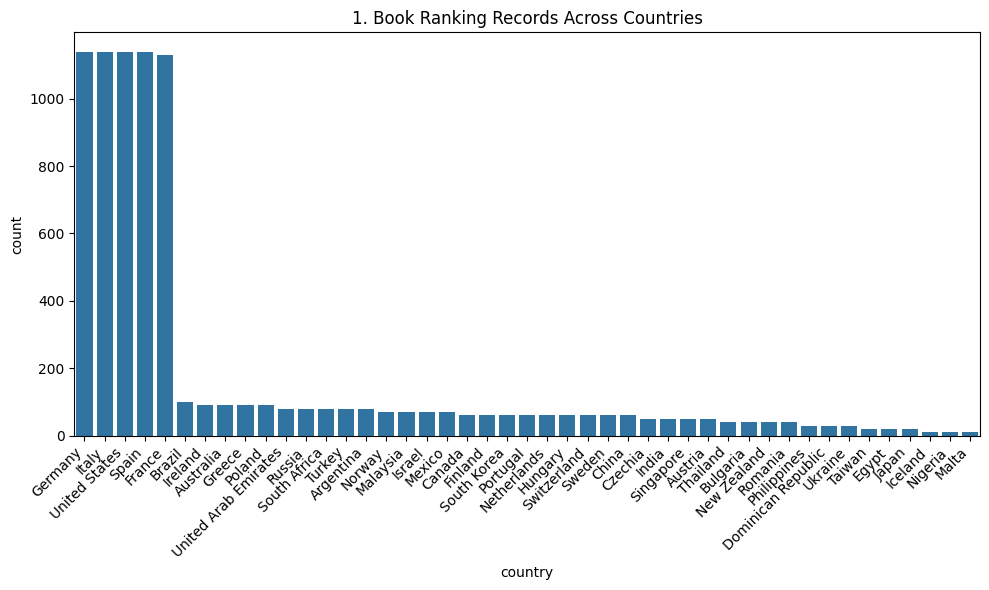

In [21]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='country', order=df['country'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Book Ranking Records Across Countries')
show_fig()
plot_no += 1

**Lecture.** Cinq barres d'environ 1 140 lignes (États-Unis, Allemagne, Italie, Espagne, France), puis une
quarantaine de pays avec 10 à 100 lignes. Ce graphique ne mesure **pas** l'importance des marchés : il mesure
la **fréquence de collecte** des données (un classement par mois pour 5 pays, environ un par an pour les
autres). C'est le biais d'échantillonnage vu en 1.6.

#### Graphique 2 : distribution des rangs

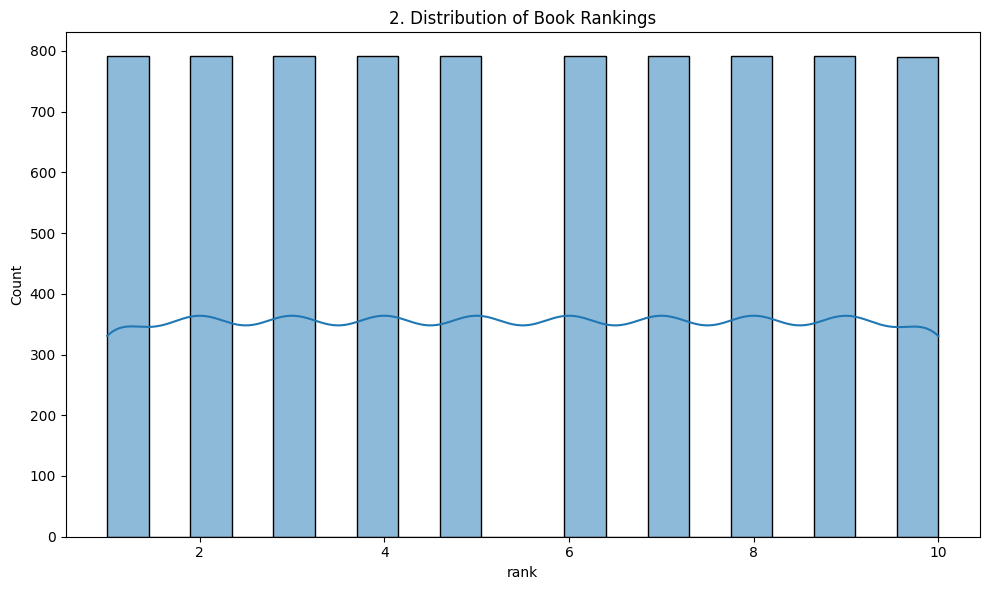

In [22]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='rank', bins=20, kde=True)
plt.title(f'{plot_no}. Distribution of Book Rankings')
show_fig()
plot_no += 1

**Correction.** Ce graphique ne contient aucune information sur les livres : chaque top 10 contient
exactement un livre de chaque rang, donc chaque rang apparaît 791 fois (790 pour le rang 10, à cause du
classement incomplet). La distribution est **uniforme par construction**. De plus :
- `bins=20` crée 20 intervalles pour seulement 10 valeurs possibles, d'où des barres vides intercalées ;
- la courbe de densité (`kde=True`) suppose une variable **continue**, alors que `rank` est une variable
  **discrète et ordinale** : la courbe ondulée n'a aucun sens.

Vérification par le calcul :

In [23]:
df['rank'].value_counts().sort_index()

rank
1     791
2     791
3     791
4     791
5     791
6     791
7     791
8     791
9     791
10    790
Name: count, dtype: int64

#### Graphique 3 : genre des auteurs

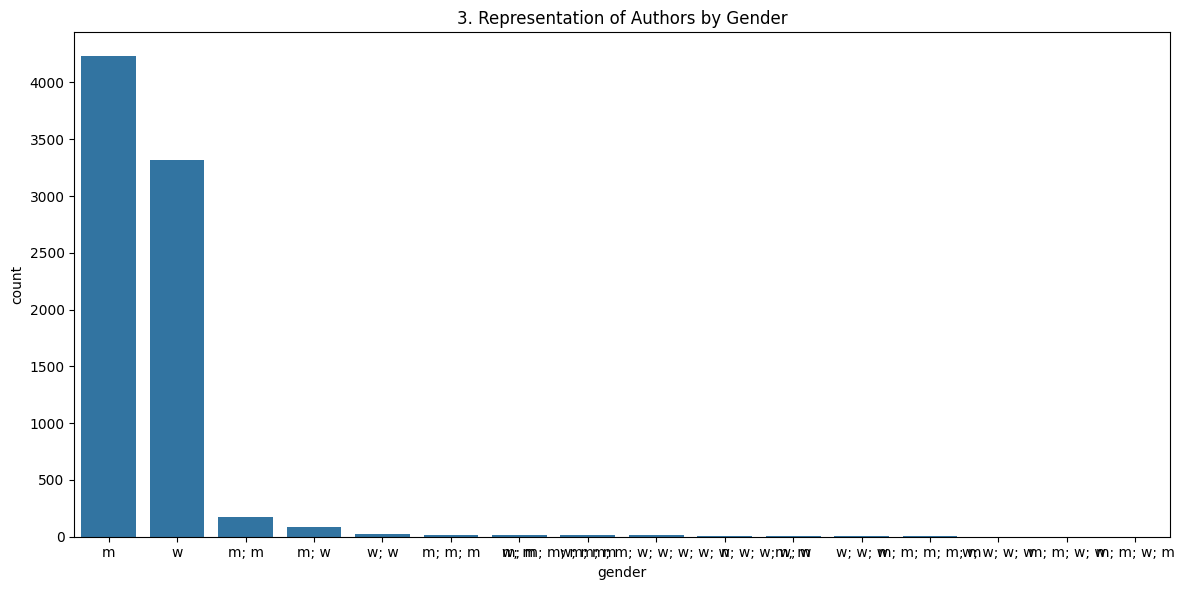

In [24]:
fig = plt.figure(figsize=(12,6))
sns.countplot(data=df, x='gender', order=df['gender'].value_counts().index)
plt.title(f'{plot_no}. Representation of Authors by Gender')
show_fig()
plot_no += 1

**Correction.** Le graphique montre 16 catégories brutes (`m`, `w`, `m; m`, `m; w`, `m, m`…) qui mélangent
le genre et le nombre de co-auteurs. On regroupe en catégories interprétables : **homme**, **femme**,
**mixte** (co-auteurs des deux genres), **non précisé** (`n`) et **inconnu** (valeur manquante).
Un livre écrit par deux hommes (`m; m`) est classé « homme » (ajout) :

genre
homme          55.9
femme          42.2
mixte           1.6
inconnu         0.1
non précisé     0.1
Name: proportion, dtype: float64


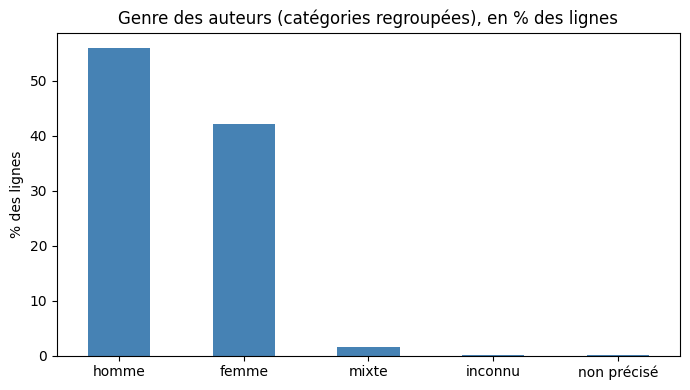

In [25]:
def genre_simplifie(valeur):
    # regroupe les codes de genre bruts en 5 catégories lisibles
    if pd.isna(valeur):
        return "inconnu"
    codes = {v.strip() for v in valeur.replace(",", ";").split(";")}   # 'm, m' est une variante de 'm; m'
    if codes == {"m"}:
        return "homme"
    if codes == {"w"}:
        return "femme"
    if codes == {"n"}:
        return "non précisé"
    return "mixte"

df["genre"] = df["gender"].map(genre_simplifie)
part_genre = df["genre"].value_counts(normalize=True).mul(100).round(1)
print(part_genre)

ax = part_genre.plot(kind="bar", figsize=(7, 4), color="steelblue")
ax.set_title("Genre des auteurs (catégories regroupées), en % des lignes")
ax.set_xlabel(""); ax.set_ylabel("% des lignes")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Lecture.** Sur l'ensemble de la période, 56 % des lignes sont des livres écrits par des hommes et 42 % par
des femmes ; les co-écritures mixtes représentent moins de 2 %. L'écart n'est pas énorme.

#### Graphique 4 : pays de publication

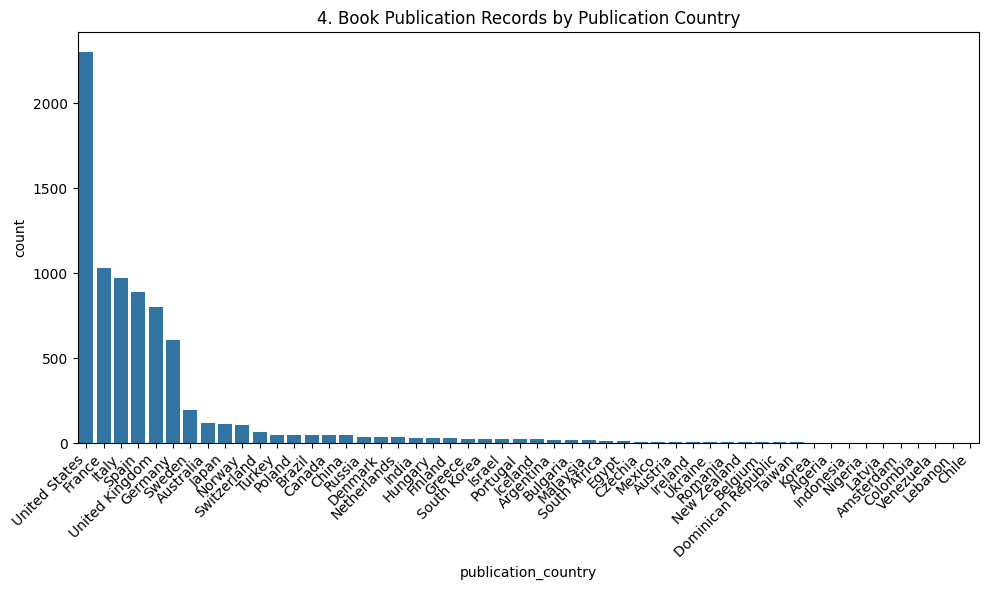

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='publication_country', order=df['publication_country'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Book Publication Records by Publication Country')
show_fig()
plot_no += 1

**Lecture.** Les États-Unis dominent (environ 2 300 lignes), suivis de la France, de l'Italie, de l'Espagne,
du Royaume-Uni et de l'Allemagne. Ce graphique combine deux effets : la sur-représentation des 5 pays suivis
chaque mois, et la **force d'exportation** des éditeurs anglophones. Le Royaume-Uni, qui n'a pas de
classement propre dans les données, apparaît en 5e position : ses livres sont donc vendus à l'étranger.

#### Graphique 5 : distribution des rangs par pays

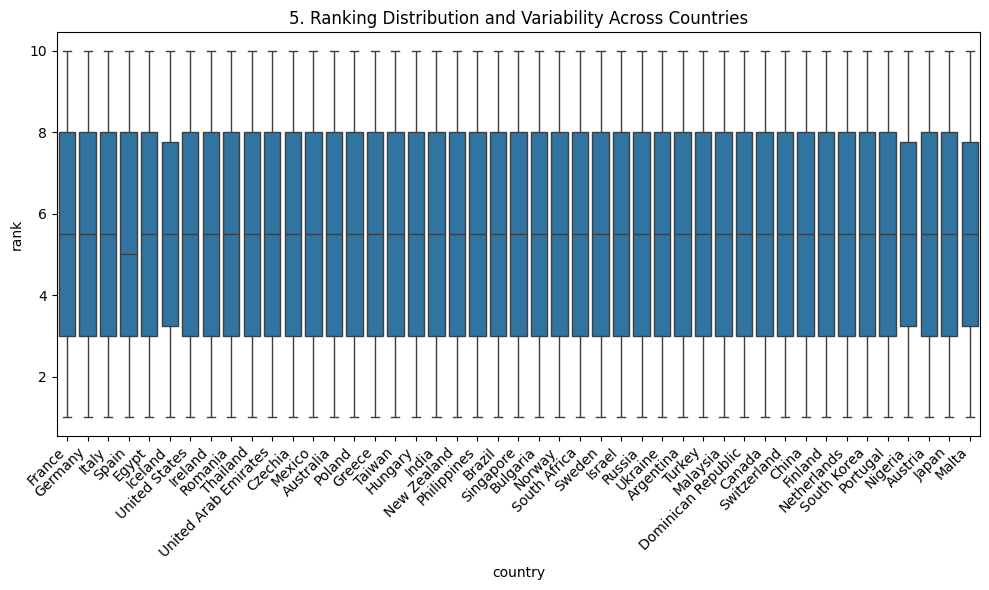

In [27]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='country', y='rank')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Ranking Distribution and Variability Across Countries')
show_fig()
plot_no += 1

**Correction.** Toutes les boîtes sont identiques (médiane 5 ou 6, quartiles environ 3 et 8), et c'est
forcé : dans **chaque** pays, chaque classement contient les rangs 1 à 10. Comparer la distribution des rangs
entre pays ne peut donc rien révéler. 

#### Graphique 6 : rangs selon le genre de l'auteur

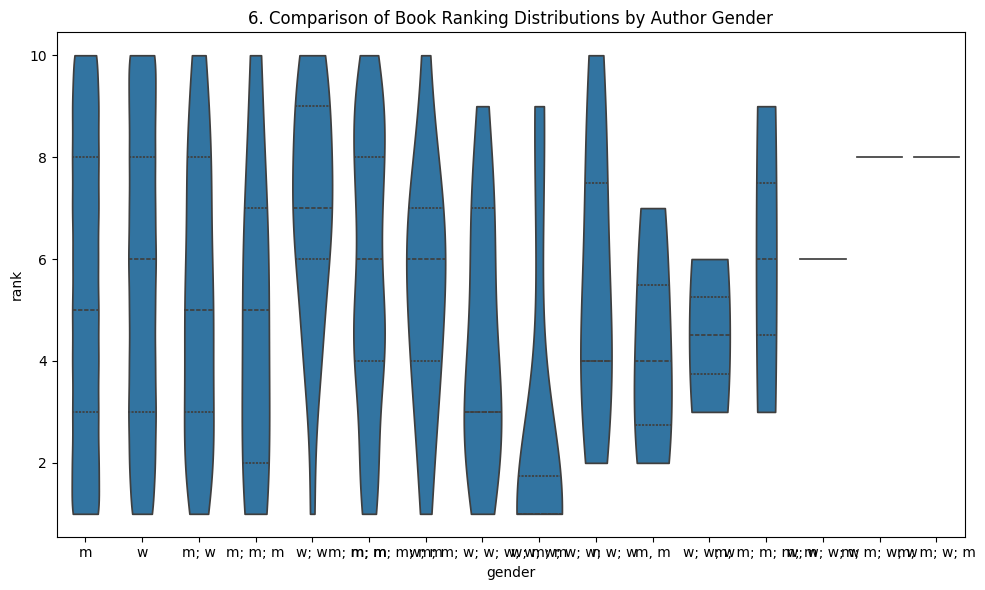

In [28]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='gender', y='rank', inner='quartile', cut=0)
plt.title(f'{plot_no}. Comparison of Book Ranking Distributions by Author Gender')
show_fig()
plot_no += 1

**Lecture et correction.** La question est pertinente : les livres écrits par des femmes sont-ils mieux ou
moins bien classés ? Mais le graphique est difficile à lire :
- il utilise les 16 catégories brutes, dont plusieurs n'ont que 1 à 20 lignes ;
- un violon lisse une variable discrète à 10 valeurs comme si elle était continue.

Une mesure plus simple et plus juste est la **part des apparitions dans le top 3**, par genre regroupé (ajout) :

In [ ]:
df["top3"] = df["rank"] <= 3
resume = df.groupby("genre").agg(lignes=("rank", "size"),
                                part_top3=("top3", "mean"),
                                rang_moyen=("rank", "mean")).round(3)
resume

,lignes,part_top3,rang_moyen
genre,,,
femme,3341,0.289,5.609
homme,4424,0.307,5.435
inconnu,10,0.300,5.100
mixte,127,0.378,4.906
non précisé,7,0.143,5.571


**Lecture.** Pour les hommes comme pour les femmes, environ **30 %** des apparitions sont dans le top 3
(29 % pour les femmes, 31 % pour les hommes), et le rang moyen est d'environ 5,5. **Une fois qu'un livre est
dans le top 10, le genre de l'auteur ne change presque rien à sa position.** Les catégories « mixte »,
« non précisé » et « inconnu » ont trop peu de lignes pour conclure.

#### Graphique 7 : genre des auteurs selon le pays du classement

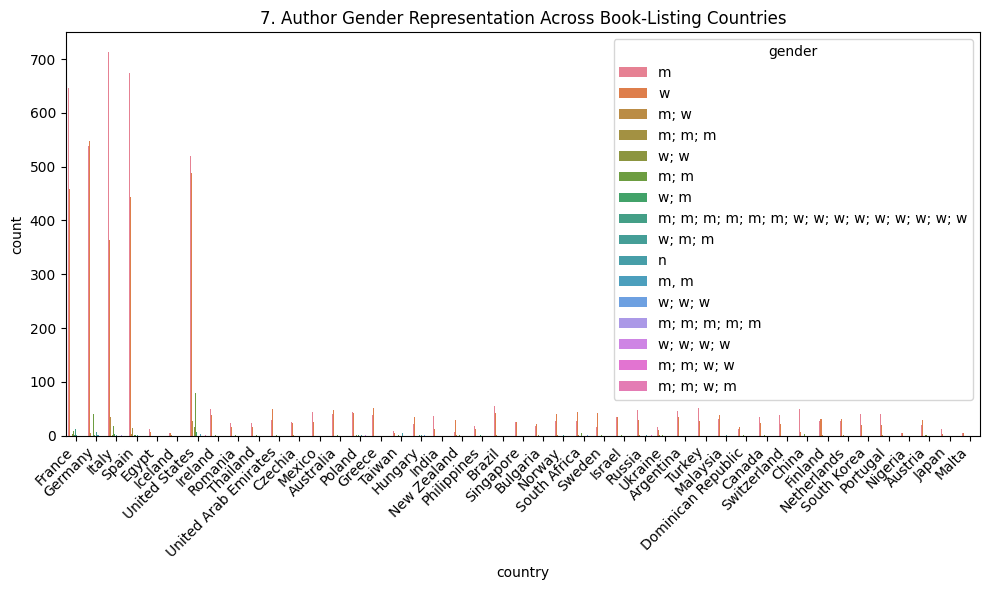

In [30]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='country', hue='gender')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Author Gender Representation Across Book-Listing Countries')
show_fig()
plot_no += 1

**Correction.** Avec des **comptages bruts**, ce graphique compare surtout le nombre de classements par
pays (5 grands pays très hauts, 40 pays minuscules), et la légende contient 16 catégories. Pour comparer les
pays, il faut des **proportions**, et se limiter aux pays qui ont assez de données. Part des femmes
parmi les auteurs, dans les 5 pays suivis chaque mois (ajout) :

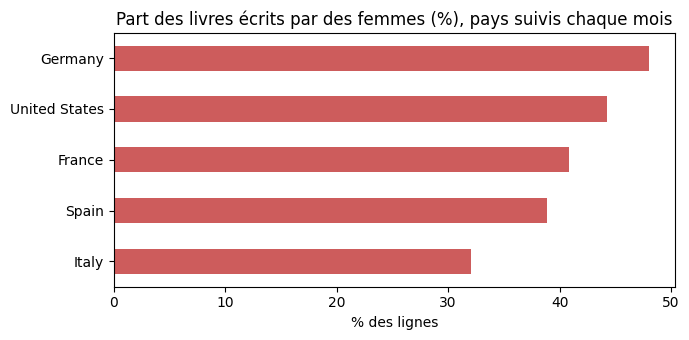

country
Italy            32.0
Spain            38.9
France           40.8
United States    44.2
Germany          48.0
Name: genre, dtype: float64

In [31]:
part_femmes = (df[df["country"].isin(grands)]
               .groupby("country")["genre"].apply(lambda g: (g == "femme").mean() * 100)
               .sort_values())
ax = part_femmes.plot(kind="barh", figsize=(7, 3.5), color="indianred")
ax.set_title("Part des livres écrits par des femmes (%), pays suivis chaque mois")
ax.set_xlabel("% des lignes"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
part_femmes.round(1)

**Lecture.** La part des livres écrits par des femmes varie nettement d'un pays à l'autre : elle est la
plus forte en Allemagne (48 %) et aux États-Unis (44 %), et la plus faible en Italie (32 %). La comparaison est fiable ici parce
que ces 5 pays ont chacun plus de 1 100 lignes, réparties sur toute la période.

#### Graphique 8 : rang en fonction du pays, par genre

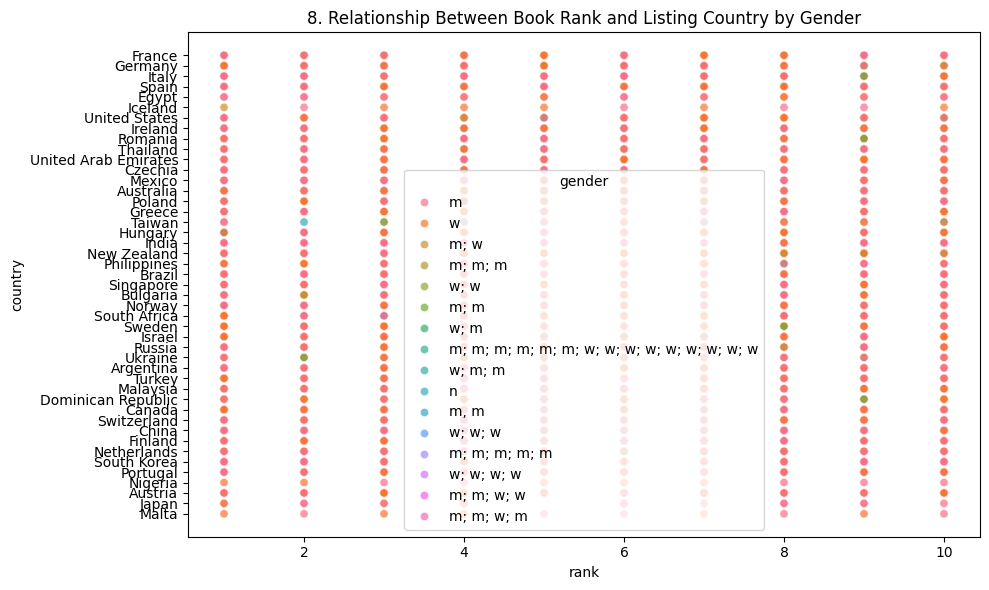

In [32]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='rank', y='country', hue='gender', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Book Rank and Listing Country by Gender')
show_fig()
plot_no += 1

**Correction.** Ce nuage de points ne peut rien montrer : les deux axes sont **discrets** (10 rangs ×
45 pays), donc des centaines de points tombent exactement au même endroit et se recouvrent. On ne voit que
la dernière couleur dessinée. De plus, chaque pays a tous les rangs par construction. Ce graphique n'apporte
aucune information ; l'information qu'il cherchait est donnée par le tableau du graphique 6.

#### Graphique 9 : genre selon le rang

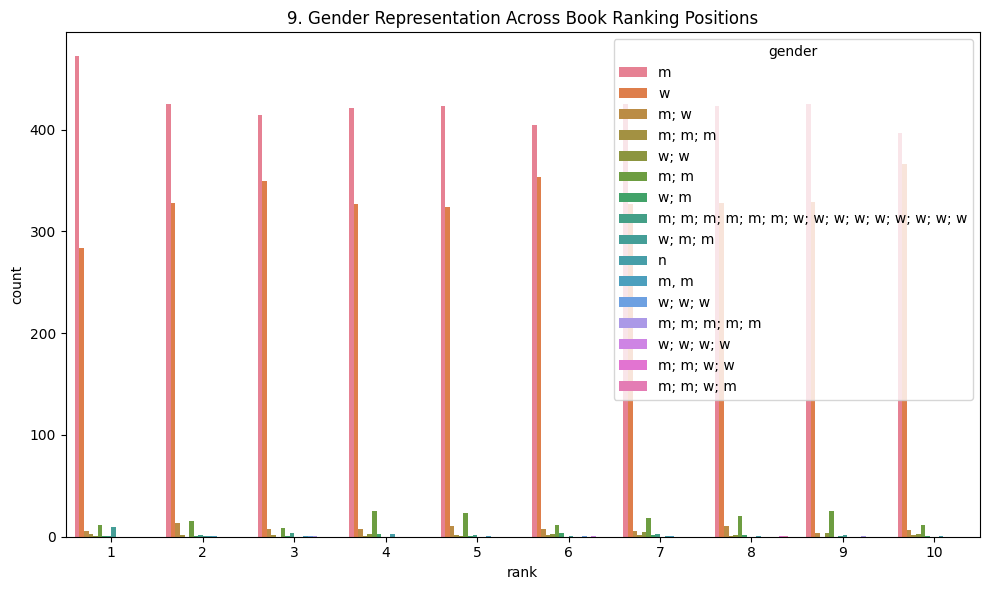

In [33]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='rank', hue='gender')
plt.title(f'{plot_no}. Gender Representation Across Book Ranking Positions')
show_fig()
plot_no += 1

**Lecture.** Pour chaque rang, les barres « m » et « w » ont à peu près la même hauteur relative : la
proportion d'hommes et de femmes est stable du rang 1 au rang 10. C'est la même conclusion que le tableau
du graphique 6 : le genre n'influence pas la position dans le top 10.

#### Graphique 10 : les 15 auteurs les plus présents

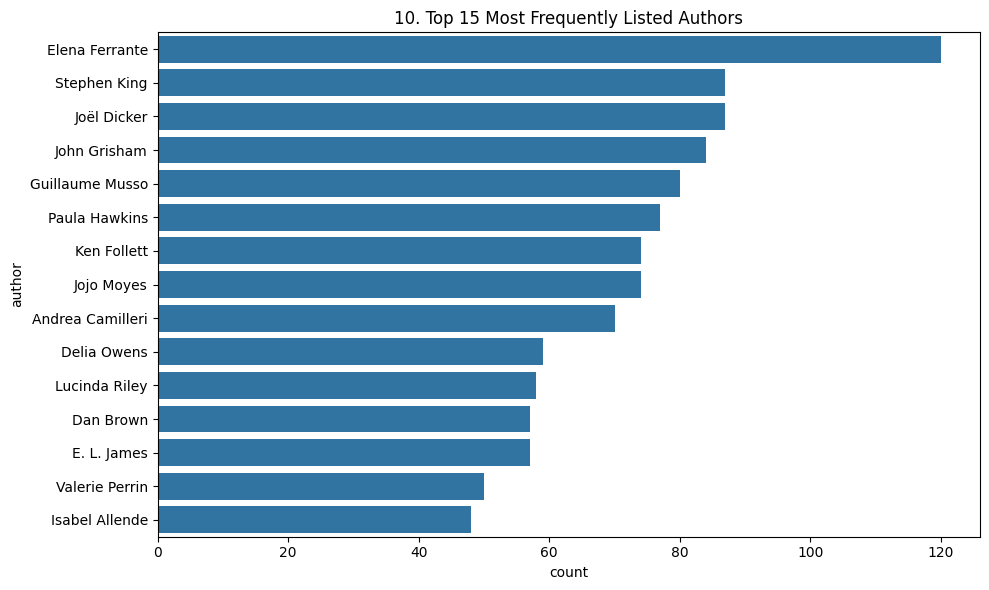

In [34]:
fig = plt.figure(figsize=(10,6))
top_authors = df['author'].value_counts().head(15).index
sns.countplot(data=df[df['author'].isin(top_authors)], y='author', order=df['author'].value_counts().head(15).index)
plt.title(f'{plot_no}. Top 15 Most Frequently Listed Authors')
show_fig()
plot_no += 1

**Lecture.** Elena Ferrante (série *L'Amie prodigieuse*) arrive en tête avec 120 apparitions, devant Stephen
King, Joël Dicker, John Grisham et Guillaume Musso. On y trouve deux profils : des auteurs **internationaux**
(King, Follett, Moyes, Hawkins), présents dans de nombreux pays, et des auteurs **très forts dans leur pays**
(Musso en France, Camilleri en Italie), dont la présence vient surtout des classements mensuels de leur pays.

#### Graphique 11 : les titres les plus présents

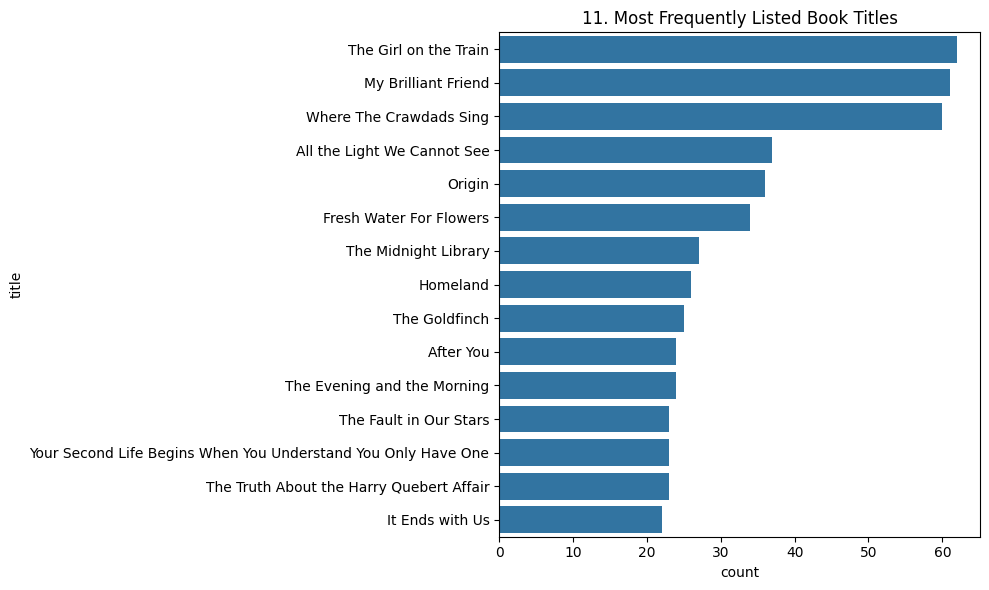

In [35]:
fig = plt.figure(figsize=(10,6))
top_titles = df['title'].value_counts().head(15).index
sns.countplot(data=df[df['title'].isin(top_titles)], y='title', order=df['title'].value_counts().head(15).index)
plt.title(f'{plot_no}. Most Frequently Listed Book Titles')
show_fig()
plot_no += 1

**Correction.** Le comptage se fait sur le **titre seul**, alors que 45 titres désignent plusieurs livres
différents (section 2.2). Le classement peut donc additionner des livres sans rapport. On refait le comptage
par couple **(titre, auteur)**, et on ajoute le nombre de pays et de mois où chaque livre apparaît (ajout) :

In [36]:
livres_top = (df.groupby(["title", "author"])
                .agg(apparitions=("rank", "size"), nb_pays=("country", "nunique"),
                     nb_mois=("date", "nunique"), meilleur_rang=("rank", "min"))
                .sort_values("apparitions", ascending=False))
livres_top.head(15)

,,apparitions,nb_pays,nb_mois,meilleur_rang
title,author,,,,
The Girl on the Train,Paula Hawkins,62,15,30,1
My Brilliant Friend,Elena Ferrante,61,11,43,1
Where The Crawdads Sing,Delia Owens,59,13,35,1
All the Light We Cannot See,Anthony Doerr,37,8,30,1
Origin,Dan Brown,36,15,13,1
Fresh Water For Flowers,Valerie Perrin,34,3,30,1
The Midnight Library,Matt Haig,27,9,18,1
Homeland,Fernando Aramburu,26,1,26,1
The Goldfinch,Donna Tartt,25,7,14,1


**Lecture.** Le podium ne change pas (*The Girl on the Train*, *My Brilliant Friend*, *Where the Crawdads
Sing*), mais la colonne `nb_pays` distingue deux types de succès :
- *The Girl on the Train* ou *All the Light We Cannot See* sont des succès **internationaux**, présents dans
  de nombreux pays ;
- certains livres cumulent beaucoup d'apparitions dans **un seul pays**, grâce à une longue présence dans
  un classement mensuel.

Cette distinction entre succès « local » et « international » servira de base à la cible du modèle de ML.

#### Graphique 12 : les 15 éditeurs les plus présents

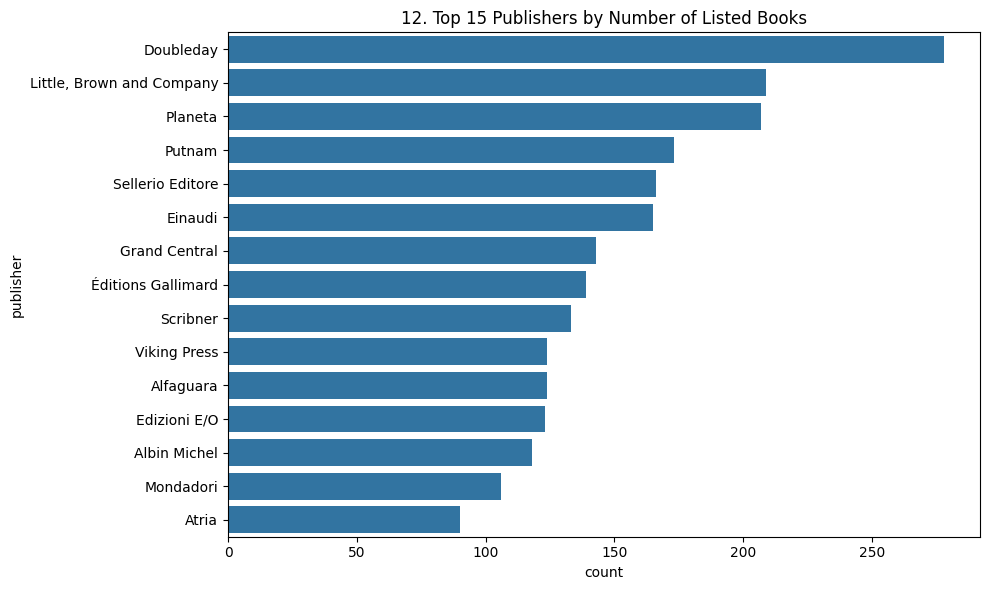

In [37]:
fig = plt.figure(figsize=(10,6))
top_publishers = df['publisher'].value_counts().head(15).index
sns.countplot(data=df[df['publisher'].isin(top_publishers)], y='publisher', order=df['publisher'].value_counts().head(15).index)
plt.title(f'{plot_no}. Top 15 Publishers by Number of Listed Books')
show_fig()
plot_no += 1

**Lecture.** Les éditeurs américains (Doubleday, Little Brown, Putnam, Grand Central, Scribner) et ceux des
grands pays suivis chaque mois (Planeta et Alfaguara en Espagne, Sellerio et Einaudi en Italie, Gallimard en
France) dominent. **Limite :** le dataset donne le nom de la **maison d'édition** (*imprint*), pas du groupe :
Doubleday, Alfaguara ou Knopf appartiennent tous à Penguin Random House. La concentration réelle du marché
est donc plus forte qu'elle n'apparaît ici.

#### Graphique 13 : composition des rangs par pays

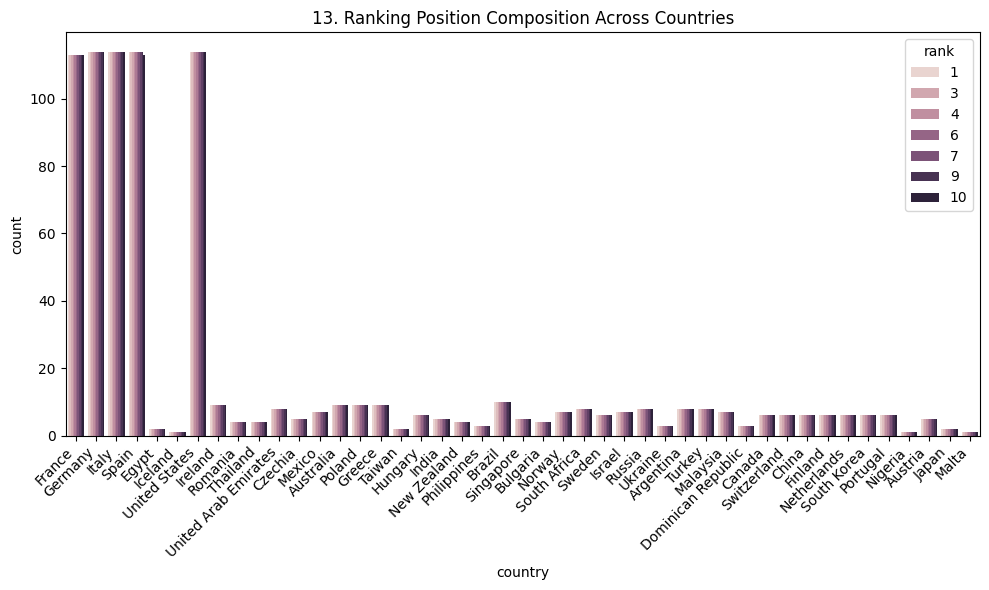

In [38]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='country', hue='rank')
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Ranking Position Composition Across Countries')
show_fig()
plot_no += 1

**Correction.** Dans chaque pays, les 10 barres ont **exactement la même hauteur**, puisque chaque
classement contient un livre de chaque rang. Le graphique ne fait que redessiner le nombre de classements par
pays (graphique 1), en dix fois.

#### Graphique 14 : rang moyen par pays

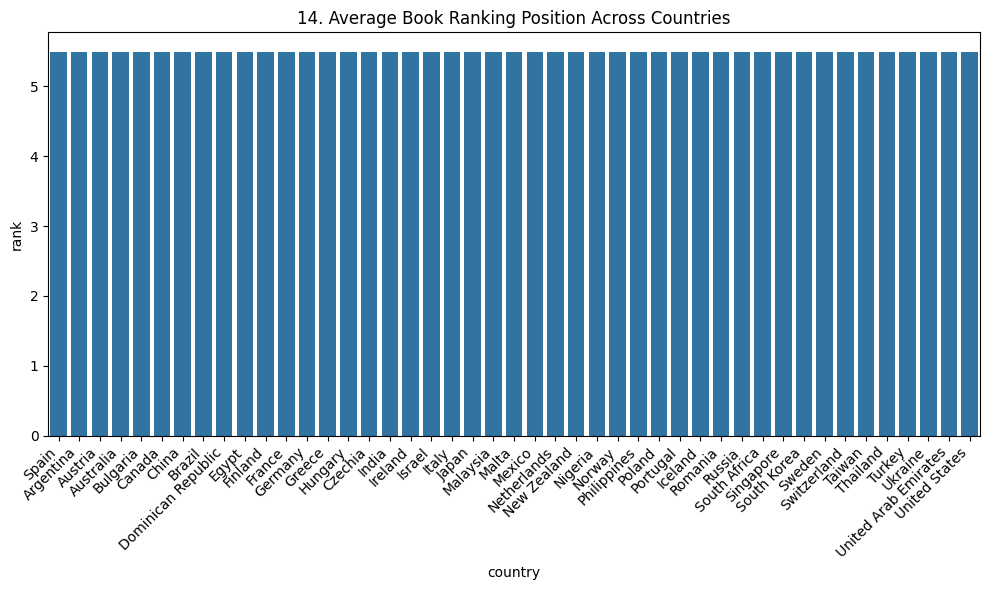

In [39]:
fig = plt.figure(figsize=(10,6))
country_rank = df.groupby('country', as_index=False)['rank'].mean().sort_values('rank')
sns.barplot(data=country_rank, x='country', y='rank', errorbar=None)
plt.xticks(rotation=45, ha='right')
plt.title(f'{plot_no}. Average Book Ranking Position Across Countries')
show_fig()
plot_no += 1

In [40]:
# vérification (ajout) : le rang moyen de chaque pays
print(country_rank["rank"].describe().round(3))

count    45.000
mean      5.500
std       0.001
min       5.496
25%       5.500
50%       5.500
75%       5.500
max       5.500
Name: rank, dtype: float64


**Correction.** Toutes les barres valent **5,5** (écart-type entre pays : 0,001). La moyenne de 1, 2, …,
10 vaut 5,5 : ce graphique est entièrement déterminé par la structure des données. Il ne dit **rien** des
pays. La seule petite différence (5,496 pour l'Espagne) vient du classement incomplet de septembre 2016.

#### Graphique 15 : éditeurs ayant le meilleur rang moyen

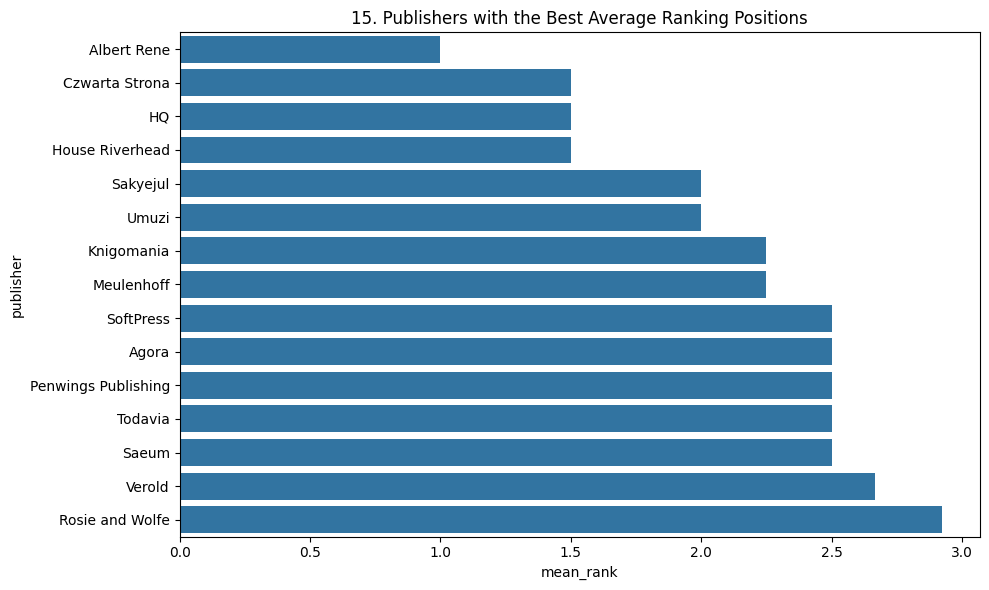

In [41]:
fig = plt.figure(figsize=(10,6))
publisher_rank = df.groupby('publisher', as_index=False).agg(mean_rank=('rank', 'mean'), listings=('rank', 'size'))
publisher_rank = publisher_rank[ publisher_rank['listings'] >= 2 ].sort_values('mean_rank').head(15)
sns.barplot(data=publisher_rank, x='mean_rank', y='publisher', errorbar=None)
plt.title(f'{plot_no}. Publishers with the Best Average Ranking Positions')
show_fig()
plot_no += 1

In [42]:
publisher_rank   # ajout : effectifs utilisés pour chaque barre

,publisher,mean_rank,listings
18,Albert Rene,1.000000,2
141,Czwarta Strona,1.500000,2
290,HQ,1.500000,2
325,House Riverhead,1.500000,2
604,Sakyejul,2.000000,2
690,Umuzi,2.000000,2
382,Knigomania,2.250000,4
457,Meulenhoff,2.250000,4
632,SoftPress,2.500000,2
11,Agora,2.500000,2


**Correction : effet de petit échantillon.** Le seuil `listings >= 2` est beaucoup trop bas : presque
tous les éditeurs du classement n'ont que **2 à 4 apparitions**. Un éditeur avec 2 livres classés 1er et 1er
obtient un rang moyen de 1, sans que cela prouve quoi que ce soit : avec si peu de données, une moyenne
extrême est le plus souvent due au hasard. Ce n'est pas le « meilleur » éditeur, c'est le plus chanceux.

On refait l'analyse avec un **seuil d'au moins 50 apparitions**, et en mesurant la part d'apparitions dans
le top 3 (ajout) :

In [43]:
editeurs = (df.groupby("publisher")
              .agg(apparitions=("rank", "size"), part_top3=("top3", "mean"), rang_moyen=("rank", "mean"))
              .query("apparitions >= 50")
              .sort_values("part_top3", ascending=False))
print("Éditeurs retenus :", len(editeurs), "| part moyenne de top 3 dans l'ensemble des données :",
      round(df["top3"].mean(), 3))
editeurs.round(3).head(10)

Éditeurs retenus : 46 | part moyenne de top 3 dans l'ensemble des données : 0.3


,apparitions,part_top3,rang_moyen
publisher,,,
Luchterhand,57,0.526,4.544
Sellerio Editore,166,0.452,4.620
Fallois,74,0.446,4.514
Tusquets,90,0.444,4.544
Plaza & Janés,77,0.429,4.792
Doubleday,278,0.414,4.719
Droemer Knaur,52,0.404,4.288
Destino,55,0.400,5.036
Flammarion,64,0.375,4.828


**Lecture.** Avec des effectifs suffisants (46 éditeurs), les écarts restent réels mais beaucoup plus
modérés : la part de top 3 va de 15 % (Alfred A. Knopf) à 53 % (Luchterhand), autour d'une moyenne de 30 %. Les éditeurs en tête
publient des auteurs « locomotives » dont chaque nouveau livre entre directement en haut du classement.

### 2.5 Analyses complémentaires (ajout)

Le notebook d'origine ne traite ni le **temps** (la colonne `date` n'est jamais utilisée), ni l'origine des
auteurs par rapport au pays du classement, ni la diffusion des livres d'un pays à l'autre. Ce sont pourtant
les questions centrales d'un dataset sur les « tendances du marché ».

#### Conversion de la date
`pd.to_datetime` convertit le texte en vraie date, ce qui permet d'extraire l'année et de trier
chronologiquement.

In [44]:
df["date"] = pd.to_datetime(df["date"])
df["annee"] = df["date"].dt.year
df.groupby("annee").size()

annee
2013    420
2014    840
2015    840
2016    839
2017    840
2018    840
2019    840
2020    840
2021    840
2022    770
dtype: int64

**Lecture.** 840 lignes par an (84 classements) de 2014 à 2021 ; 2013 et 2022 sont incomplètes (la collecte
commence en juin 2013, et deux mois de 2022 manquent pour la France).

#### Évolution de la part des autrices
Pour éviter le biais de composition (la liste des « petits » pays change chaque année), on calcule
l'évolution **sur les 5 pays suivis chaque mois** uniquement.

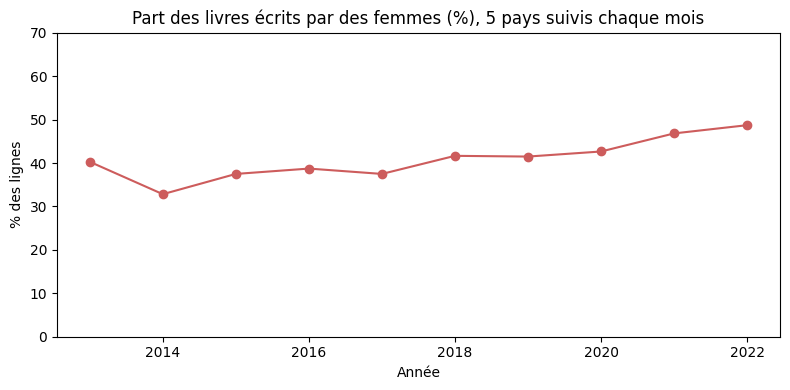

annee
2013    40.3
2014    32.8
2015    37.5
2016    38.7
2017    37.5
2018    41.7
2019    41.5
2020    42.7
2021    46.8
2022    48.7
Name: genre, dtype: float64

In [45]:
evol_genre = (df[df["country"].isin(grands)]
              .groupby("annee")["genre"].apply(lambda g: (g == "femme").mean() * 100))
ax = evol_genre.plot(marker="o", figsize=(8, 4), color="indianred")
ax.set_title("Part des livres écrits par des femmes (%), 5 pays suivis chaque mois")
ax.set_xlabel("Année"); ax.set_ylabel("% des lignes"); ax.set_ylim(0, 70)
plt.tight_layout(); plt.show()
evol_genre.round(1)

**Lecture.** C'est l'une des tendances les plus nettes du dataset : la part des livres écrits par des
femmes dans les top 10 **augmente régulièrement**, de 33 % en 2014 à 49 % en 2022, presque la parité.
La valeur de 2013 (40 %) repose sur 7 mois seulement. Cette évolution est
mesurée sur les mêmes pays chaque année : elle n'est donc pas un artefact de la composition de l'échantillon.

#### Auteurs locaux ou étrangers
Un auteur est « local » si sa nationalité est celle du pays du classement. Pour les co-auteurs, il suffit
qu'un des auteurs ait cette nationalité.

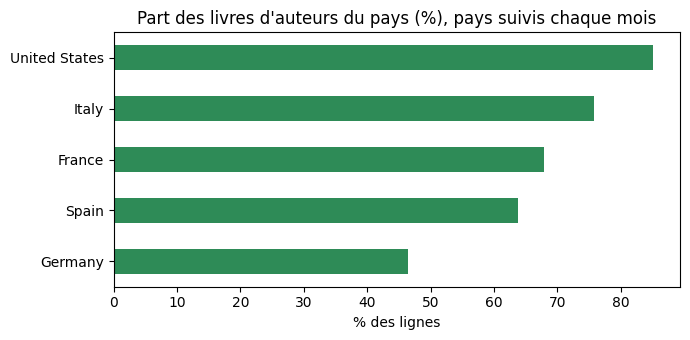

country
Germany          46.491228
Spain            63.827919
France           67.876106
Italy            75.746924
United States    85.087719
Name: auteur_local, dtype: object

In [50]:
def est_local(ligne):
    if pd.isna(ligne["nationality"]):
        return np.nan
    # les co-auteurs sont séparés par ";" ou parfois par "," (incohérence traitée au prétraitement)
    nationalites = [n.strip() for n in ligne["nationality"].replace(",", ";").split(";")]
    return ligne["country"] in nationalites

df["auteur_local"] = df.apply(est_local, axis=1)
part_local = (df[df["country"].isin(grands)]
              .groupby("country")["auteur_local"].mean().mul(100).sort_values())
ax = part_local.plot(kind="barh", figsize=(7, 3.5), color="seagreen")
ax.set_title("Part des livres d'auteurs du pays (%), pays suivis chaque mois")
ax.set_xlabel("% des lignes"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
part_local.round(1)

**Lecture.** Les marchés sont très différents :
- aux **États-Unis**, 85 % des best-sellers sont écrits par des auteurs américains : le marché est
  **très fermé** aux traductions ;
- en **Italie** (76 %), en **France** (68 %) et en **Espagne** (64 %), les auteurs nationaux dominent aussi ;
- l'**Allemagne** est le marché le plus **ouvert** : moins de la moitié des best-sellers sont d'auteurs
  allemands.

**Conséquence pour le ML :** le pays où un livre apparaît est fortement lié à l'origine de son auteur ; ces
deux informations seront des variables importantes.

#### Diffusion internationale des livres
On passe maintenant au niveau du **livre** (couple titre + auteur) : dans combien de pays différents
chaque livre a-t-il été classé ?

Nombre de livres distincts : 3800
nb_pays
1     3336
2      264
3       79
4       37
5       28
6       20
7       13
8        8
9        7
10       2
Name: count, dtype: int64
Part des livres classés dans au moins 2 pays : 12.2%


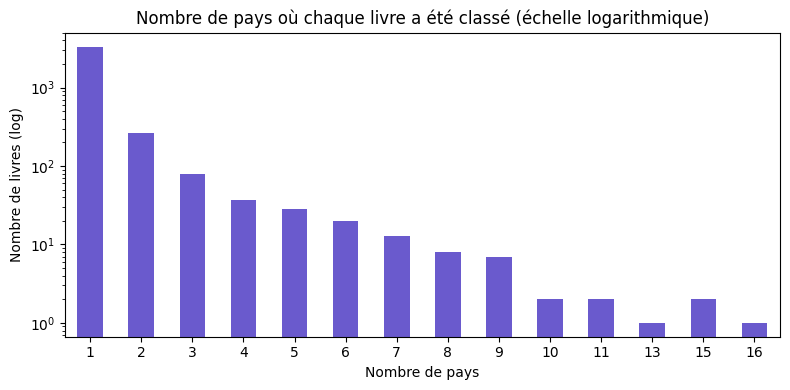

In [47]:
livres = df.groupby(["title", "author"]).agg(nb_pays=("country", "nunique"),
                                             apparitions=("rank", "size"))
print("Nombre de livres distincts :", len(livres))
repartition = livres["nb_pays"].value_counts().sort_index()
print(repartition.head(10))
print(f"Part des livres classés dans au moins 2 pays : {(livres['nb_pays'] >= 2).mean():.1%}")

ax = repartition.plot(kind="bar", figsize=(8, 4), color="slateblue", logy=True)
ax.set_title("Nombre de pays où chaque livre a été classé (échelle logarithmique)")
ax.set_xlabel("Nombre de pays"); ax.set_ylabel("Nombre de livres (log)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Lecture.** La distribution est extrêmement asymétrique : **88 % des livres ne sont classés que dans un seul
pays**, et seuls 12 % franchissent une frontière. Quelques livres atteignent 10 à 13 pays. L'échelle
logarithmique est nécessaire, sinon la barre « 1 pays » (3 336 livres) écraserait toutes les autres.

C'est la question la plus intéressante pour un modèle : **qu'est-ce qui distingue un best-seller
international d'un best-seller seulement national ?**

### 2.6 Synthèse de l'EDA et conséquences pour la suite

| Constat | Conséquence |
|---|---|
| Pas de chiffres de ventes ; `rank` est uniforme par construction | `rank` ne peut pas servir à comparer pays, genres ou années ; la notion de succès doit être construite |
| 5 pays suivis chaque mois, 40 pays environ une fois par an | biais d'échantillonnage : comparaisons sur les 5 grands pays, ou en proportions |
| 12 valeurs manquantes, dont des ouvrages collectifs | pas de remplissage par le mode : catégorie « inconnu » |
| Un même titre peut désigner plusieurs livres ; un livre peut apparaître deux fois dans un classement | identifier les livres par (titre, auteur) ; compter les apparitions avec précaution |
| `gender` a 16 codes bruts | regroupement en 5 catégories |
| Plusieurs graphiques d'origine ne montrent qu'un effet de construction | ils sont conservés mais signalés, et remplacés par des analyses en proportions |
| 12 % des livres deviennent internationaux | cible naturelle pour le ML, avec des **classes déséquilibrées** |

## 3. Prétraitement

**Objectif.** Produire un jeu de données **propre et cohérent**, en gardant une ligne par apparition dans un
classement. Chaque correction est **justifiée par un constat de l'EDA ou par une vérification**, et son
effet est contrôlé.

Principe suivi : on ne modifie une valeur que si l'on sait **quelle est la bonne valeur**. Dans le cas
contraire, on la marque comme inconnue plutôt que d'inventer une information.

On repart des données brutes, pour que le prétraitement soit complet et reproductible indépendamment des
colonnes ajoutées pendant l'EDA.

In [51]:
dfp = df_raw.copy()      # dfp : données en cours de prétraitement
print(dfp.shape)

(7909, 10)


### 3.1 Valeurs manquantes

**Code d'origine.** Le notebook d'origine remplace chaque valeur manquante par la valeur la plus fréquente
(le *mode*). On l'applique sur une **copie**, pour montrer son effet (ajout) :

In [52]:
test_mode = dfp.copy()
manquantes = test_mode[["nationality", "gender", "publisher"]].isnull().any(axis=1)

# --- code d'origine ---
test_mode['nationality'] = test_mode['nationality'].fillna(test_mode['nationality'].mode()[0])
test_mode['gender'] = test_mode['gender'].fillna(test_mode['gender'].mode()[0])
test_mode['publisher'] = test_mode['publisher'].fillna(test_mode['publisher'].mode()[0])

test_mode.loc[manquantes, ["title", "author", "country", "nationality", "gender", "publisher", "publication_country"]]

,title,author,country,nationality,gender,publisher,publication_country
61,Fine Print,Lauren Asher,Singapore,United States,w,KDP,United States
473,Traveling In Yellow,[Various],Italy,United States,m,Sellerio Editore,Italy
1255,Traveling In Yellow,[Various],Italy,United States,m,Sellerio Editore,Italy
1456,Not The Other Party,Cheer,Taiwan,United States,m,Life Publishing Ltd,China
1643,Terms and Conditions,Lauren Asher,Singapore,United States,w,Piatkus,United Kingdom
3629,Material Collector's World Tour Book 2,Kinoko Tetsu,Japan,Japan,m,Doubleday,Japan
3694,Coffee Scented Stories,[Various],Turkey,United States,m,Yakamoz Yayınları,Turkey
3713,VRMMO Symbol 9,Shiina HowaHowa,Japan,United States,m,AlphaPolis,Japan
4524,Once Again The Course Dealing With Disappointm...,Herman Hermits,Netherlands,United States,m,Thomas Rap,Netherlands
5211,Fairy Tale: Chronicle Air 14,Haniwa Star Man,Japan,Japan,m,Doubleday,Japan


**Correction : pourquoi on n'applique pas ce remplissage.**
- **Il invente des informations fausses**, et non des approximations : des light novels japonais publiés au
  Japon reçoivent la nationalité américaine et l'éditeur américain Doubleday ; des recueils collectifs
  (`[Various]`) reçoivent un genre masculin.
- **Il fausse les analyses** : chaque valeur inventée ajoute une fausse paire « auteur américain classé au
  Japon », c'est-à-dire un faux succès international, exactement ce que le modèle cherchera à prédire.
- Le remplissage par le mode n'est acceptable que si les valeurs manquent **au hasard** et que la variable
  a une valeur très dominante. Ici, les valeurs manquent pour une **raison précise** (ouvrages collectifs,
  auteurs peu documentés) : ce n'est pas le cas.

**Choix retenu :** une catégorie explicite **`Inconnu`**.

| Option | Effet | Décision |
|---|---|---|
| Supprimer les 12 lignes | perte de 0,15 % des lignes, et des classements qui n'auraient plus 10 livres | rejetée : on perd de l'information sans raison |
| Remplir par le mode | invente des valeurs fausses | rejetée |
| Catégorie `Inconnu` | aucune valeur inventée ; le modèle peut traiter « inconnu » comme une catégorie | **retenue** |

In [53]:
for colonne in ["nationality", "publisher"]:
    dfp[colonne] = dfp[colonne].fillna("Inconnu")
# le genre est traité en 3.4 (regroupement), où la valeur manquante devient la catégorie "inconnu"
print(dfp[["nationality", "publisher"]].isnull().sum())

nationality    0
publisher      0
dtype: int64


### 3.2 Uniformisation des textes

Pour comparer deux colonnes (par exemple, la nationalité de l'auteur et le pays du classement), il faut que
les mêmes choses soient écrites de la même façon. On vérifie toutes les colonnes texte.

**Espaces parasites.**

In [54]:
colonnes_texte = ["country", "title", "author", "nationality", "gender", "publisher", "publication_country"]
for c in colonnes_texte:
    valeurs = dfp[c].dropna()
    print(f"{c:20s} espaces au bord : {(valeurs != valeurs.str.strip()).sum():3d} | "
          f"doubles espaces : {valeurs.str.contains('  ').sum()}")

country              espaces au bord :   0 | doubles espaces : 0
title                espaces au bord :   0 | doubles espaces : 0
author               espaces au bord :   0 | doubles espaces : 0
nationality          espaces au bord :   0 | doubles espaces : 1
gender               espaces au bord :   0 | doubles espaces : 0
publisher            espaces au bord :   0 | doubles espaces : 0
publication_country  espaces au bord :   0 | doubles espaces : 0


**Séparateurs entre co-auteurs.** Dans `nationality`, les co-auteurs sont séparés tantôt par `;`, tantôt par
`,` : `"Australia, United States"` désigne deux nationalités, pas un pays nommé « Australia, United States ».

In [55]:
print("nationality avec ';' :", dfp["nationality"].str.contains(";").sum(),
      "| avec ',' :", dfp["nationality"].str.contains(",").sum())
dfp.loc[dfp["nationality"].str.contains(","), "nationality"].value_counts().head(8)

nationality avec ';' : 311 | avec ',' : 140


nationality
United States, Afghanistan                      28
Egypt, United States                            12
Germany, Bosnia and Herzegovina                 12
Singapore, United States                        11
Greece, Turkey                                   9
Israel, United States                            6
United Kingdom, South Africa; United Kingdom     5
United Kingdom, South Africa                     4
Name: count, dtype: int64

In [56]:
def nettoyer_liste(valeur):
    # uniformise une liste de valeurs : séparateur '; ', espaces superflus supprimés
    morceaux = [m.strip() for m in valeur.replace(",", ";").split(";")]
    return "; ".join(m for m in morceaux if m)

dfp["nationality"] = dfp["nationality"].map(nettoyer_liste)
dfp["gender"] = dfp["gender"].map(lambda g: g if pd.isna(g) else nettoyer_liste(g))
for c in colonnes_texte:
    dfp[c] = dfp[c].str.strip().str.replace(r"\s+", " ", regex=True)   # espaces multiples -> un seul
print("nationality avec ',' après nettoyage :", dfp["nationality"].str.contains(",").sum())

nationality avec ',' après nettoyage : 0


**Noms de pays incohérents.** On compare les noms utilisés dans les trois colonnes de pays : chaque
nationalité devrait correspondre à un pays nommé de la même façon.

In [57]:
pays_classement = set(dfp["country"])
pays_edition = set(dfp["publication_country"])
nationalites = {n for liste in dfp["nationality"] for n in liste.split("; ")}

print("Nationalités absentes des deux autres colonnes :")
print(sorted(nationalites - pays_classement - pays_edition))
print("\nPays d'édition absents des pays de classement :")
print(sorted(pays_edition - pays_classement))

Nationalités absentes des deux autres colonnes :
['Afghanistan', 'Algiers', 'Angola', 'Armenia', 'Azerbaijan', 'Bosnia and Herzegovina', 'Cameroon', 'Cuba', 'Cyprus', 'Czech Republic', 'Estonia', 'Georgia', 'Haiti', 'Inconnu', 'Iran', 'Iraq', 'Ivory Coast', 'Jamaica', 'Kazakhstan', 'Morocco', 'Morroco', 'Mozambique', 'Pakistan', 'Peru', 'Rwanda', 'Scotland', 'Senegal', 'Sri Lanka', 'Syria', 'Tanzania', 'Trinidad and Tobago', 'Uganda', 'Uruguay', 'Vietnam']

Pays d'édition absents des pays de classement :
['Algeria', 'Amsterdam', 'Belgium', 'Chile', 'Colombia', 'Denmark', 'Indonesia', 'Korea', 'Latvia', 'Lebanon', 'United Kingdom', 'Venezuela']


**Lecture.** La plupart des valeurs sont de vrais pays, simplement absents des classements (Maroc, Cuba,
Iran…). Mais certaines sont des **erreurs ou des incohérences de nommage** :

| Valeur | Problème | Correction |
|---|---|---|
| `Morroco` | faute de frappe (on trouve aussi `Morocco`) | `Morocco` |
| `Algiers` | c'est la capitale, pas le pays | `Algeria` |
| `Czech Republic` | ancien nom ; le pays de classement s'appelle `Czechia` | `Czechia` |
| `Scotland` | nation constitutive du Royaume-Uni ; les autres auteurs britanniques sont notés `United Kingdom` | `United Kingdom` |
| `Amsterdam` (pays d'édition) | ville, pas pays | `Netherlands` |
| `Korea` (pays d'édition) | ambigu ; il s'agit d'éditeurs sud-coréens | `South Korea` |

**Pourquoi c'est important.** Sans ces corrections, un auteur tchèque classé en Tchéquie ne serait pas reconnu
comme « local » (`Czech Republic` ≠ `Czechia`), et `Morocco` et `Morroco` compteraient comme deux pays.

In [58]:
corrections_pays = {"Morroco": "Morocco", "Algiers": "Algeria", "Czech Republic": "Czechia",
                    "Scotland": "United Kingdom", "Amsterdam": "Netherlands", "Korea": "South Korea"}

def corriger_pays(liste):
    return "; ".join(corrections_pays.get(n, n) for n in liste.split("; "))

avant = dfp["nationality"].copy()
dfp["nationality"] = dfp["nationality"].map(corriger_pays)
dfp["publication_country"] = dfp["publication_country"].replace(corrections_pays)
print("Lignes modifiées dans nationality :", (avant != dfp["nationality"]).sum())

Lignes modifiées dans nationality : 11


**Variantes d'un même éditeur ou d'un même titre.** On cherche les valeurs qui ne diffèrent que par la casse
(majuscules / minuscules), la ponctuation ou les espaces.

In [59]:
def cle(texte):
    # clé de comparaison : minuscules, sans ponctuation ni espaces
    return texte.lower().replace(" ", "").translate(str.maketrans("", "", ".,;:!?'-\"()"))

for colonne in ["publisher", "title"]:
    groupes = dfp.groupby(dfp[colonne].map(cle))[colonne].unique()
    variantes = groupes[groupes.map(len) > 1]
    print(f"{colonne} : {len(variantes)} groupes de variantes")
    for v in variantes:
        auteurs = dfp.loc[dfp[colonne].isin(v), ["author", colonne]].drop_duplicates().values.tolist()
        print("   ", auteurs)

publisher : 1 groupes de variantes
    [['Emmanuel Carrère', 'Pol'], ['Jo Nesbø', 'Pol'], ['Emmanuel Carrère', 'P.O.L']]
title : 6 groupes de variantes
    [['[Various]', '13 At The Table!'], ['[Various]', '13 At the Table!']]
    [['Jonathan Franzen', 'Crossroads'], ['William P. Young', 'Cross Roads']]
    [['Stephen King', 'Fairy Tale'], ['Danielle Steel', 'Fairytale']]
    [['Marian Keyes', 'Grown Ups'], ['Marie Aubert', 'Grown-ups']]
    [['Harlan Coben', 'Run Away'], ['Alice Munro', 'Runaway']]
    [['Michael Connelly', 'The Law Of Innocence'], ['Michael Connelly', 'The Law of Innocence']]


**Lecture et décision.** Une ressemblance d'écriture ne prouve pas qu'il s'agit du même objet :
- `Pol` et `P.O.L` sont le même éditeur français, celui d'Emmanuel Carrère : **fusionnés** ;
- **erreur dans les données :** deux lignes attribuent l'éditeur `Pol` (pays d'édition `France`) à
  *The Kingdom* de **Jo Nesbø**, un auteur norvégien qui n'est pas publié par P.O.L. Emmanuel Carrère a
  publié un livre au **même titre**, *The Kingdom*, chez P.O.L : les informations d'édition de Carrère ont
  visiblement été recopiées sur le livre de Nesbø en rapprochant les livres par leur **titre seul**. Comme
  on ne connaît pas avec certitude l'éditeur à retenir, on marque ces deux valeurs comme `Inconnu` ;
- *The Law Of Innocence* / *The Law of Innocence* (Michael Connelly) et *13 At The Table!* / *13 At the Table!*
  (ouvrage collectif) sont le même livre : **fusionnés** ;
- *Fairy Tale* (Stephen King) et *Fairytale* (Danielle Steel), *Run Away* (Harlan Coben) et *Runaway*
  (Alice Munro), *Crossroads* et *Cross Roads*, *Grown Ups* et *Grown-ups* sont des **livres différents
  d'auteurs différents** : **conservés séparés**.

**Règle retenue :** deux lignes désignent le même livre si elles ont le même **titre normalisé** (la clé
ci-dessus) **et** le même **auteur**. Cette règle fusionne exactement les deux vrais doublons, sans fusionner
les livres différents.

In [60]:
# éditeur et pays d'édition recopiés par erreur depuis "The Kingdom" d'Emmanuel Carrère
erreur_nesbo = (dfp["author"] == "Jo Nesbø") & (dfp["title"] == "The Kingdom") & (dfp["publisher"] == "Pol")
print("Lignes Jo Nesbø corrigées :", erreur_nesbo.sum())
dfp.loc[erreur_nesbo, ["publisher", "publication_country"]] = "Inconnu"
dfp["publisher"] = dfp["publisher"].replace({"Pol": "P.O.L"})
dfp["livre_id"] = dfp["title"].map(cle) + " | " + dfp["author"]

print("Livres distincts avec (titre, auteur) bruts    :", dfp.groupby(["title", "author"]).ngroups)
print("Livres distincts avec livre_id (titre normalisé):", dfp["livre_id"].nunique())

Lignes Jo Nesbø corrigées : 2
Livres distincts avec (titre, auteur) bruts    : 3800
Livres distincts avec livre_id (titre normalisé): 3798


### 3.3 Types et dates
`date` est convertie en vraie date. On vérifie que toutes les dates sont des premiers du mois, sans valeur
impossible, et on extrait l'année et le mois.

In [61]:
dfp["date"] = pd.to_datetime(dfp["date"], errors="raise")   # errors='raise' : erreur si une date est invalide
print("Toutes les dates sont des 1ers du mois :", (dfp["date"].dt.day == 1).all())
print("Plage :", dfp["date"].min().date(), "->", dfp["date"].max().date())
dfp["annee"] = dfp["date"].dt.year
dfp["mois"] = dfp["date"].dt.month

Toutes les dates sont des 1ers du mois : True
Plage : 2013-06-01 -> 2022-12-01


### 3.4 Genre et nombre d'auteurs
On remplace les 16 codes bruts de `gender` par les 5 catégories définies pendant l'EDA. La valeur manquante
devient `inconnu`. On en profite pour créer `nb_auteurs` : le nombre de codes de genre est le nombre d'auteurs.

In [62]:
dfp["genre"] = dfp["gender"].map(genre_simplifie)       # fonction définie en 2.4
dfp["nb_auteurs"] = dfp["gender"].map(lambda g: np.nan if pd.isna(g) else len(g.split("; ")))
print(dfp["genre"].value_counts())
print(dfp["nb_auteurs"].value_counts(dropna=False).sort_index())

genre
homme          4424
femme          3341
mixte           127
inconnu          10
non précisé       7
Name: count, dtype: int64
nb_auteurs
1.0     7553
2.0      295
3.0       33
4.0        3
5.0        2
15.0      13
NaN       10
Name: count, dtype: int64


**Lecture.** 96 % des livres ont un seul auteur. Le cas de 15 auteurs correspond à un recueil collectif
(13 lignes). `nb_auteurs` est inconnu pour les 10 lignes sans genre : il sera complété à 1 (valeur
largement dominante) au moment de la transformation, avec un indicateur « valeur manquante ».

### 3.5 Auteur local
La variable `auteur_local` (vrai si l'un des auteurs a la nationalité du pays du classement) est recalculée
**sur les nationalités nettoyées** ; elle est inconnue quand la nationalité est inconnue.

In [63]:
def local(ligne):
    if ligne["nationality"] == "Inconnu":
        return np.nan
    return float(ligne["country"] in ligne["nationality"].split("; "))

dfp["auteur_local"] = dfp.apply(local, axis=1)
print(dfp["auteur_local"].value_counts(dropna=False))

auteur_local
1.0    4537
0.0    3362
NaN      10
Name: count, dtype: int64


### 3.6 Doublons
- **Doublons exacts :** aucun (vérifié en 2.2).
- **Même livre deux fois dans le même classement :** on les recherche avec le nouvel identifiant `livre_id`.

In [64]:
doublons = dfp.duplicated(["date", "country", "livre_id"], keep=False)
print("Lignes concernées :", doublons.sum())
dfp.loc[doublons, ["date", "country", "rank", "title", "author", "publisher"]].sort_values(["date", "country"])

Lignes concernées : 16


,date,country,rank,title,author,publisher
637,2015-04-01,Italy,1,Moments Of Negligible Happiness,Francesco Piccolo,Einaudi
2219,2015-04-01,Italy,3,Moments Of Negligible Happiness,Francesco Piccolo,Einaudi
5978,2017-08-01,China,8,Ordinary World,Lu Yao,Beijing October Literature and Arts Press
7560,2017-08-01,China,10,Ordinary World,Lu Yao,Beijing October Literature and Arts Press
1165,2018-06-01,Mexico,2,The Little Prince,Antoine de Saint-Exupéry,Éditions Gallimard
4329,2018-06-01,Mexico,6,The Little Prince,Antoine de Saint-Exupéry,Éditions Gallimard
1939,2018-08-01,China,3,Ordinary World,Lu Yao,Beijing October Literature and Arts Press
4312,2018-08-01,China,6,Ordinary World,Lu Yao,Beijing October Literature and Arts Press
4169,2020-05-01,Philippines,6,P.S. I Still Love You,Jenny Han,Simon & Schuster
4960,2020-05-01,Philippines,7,P.S. I Still Love You,Jenny Han,Simon & Schuster


**Décision : on garde ces lignes.** Elles reflètent une réalité (deux éditions du même livre classées en même
temps), et les supprimer retirerait un rang du classement. **Conséquence :** pour compter dans combien de
classements un livre apparaît, on comptera les couples **(date, pays) distincts**, et non les lignes. C'est
ce que fera la transformation.

### 3.7 Valeurs aberrantes
Il n'y a qu'une variable numérique, `rank`. On vérifie qu'elle reste dans son domaine de valeurs.

In [65]:
print("rank hors de 1..10 :", (~dfp["rank"].between(1, 10)).sum())
print("Auteurs '[Various]' (ouvrages collectifs) :", (dfp["author"] == "[Various]").sum())

rank hors de 1..10 : 0
Auteurs '[Various]' (ouvrages collectifs) : 35


**Lecture.** Aucune valeur aberrante au sens numérique. Pour des variables catégorielles, l'équivalent des
valeurs aberrantes, ce sont les **catégories très rares** (un éditeur ou une nationalité présents une seule
fois) : elles sont traitées à l'étape de transformation, en les regroupant dans une catégorie « autre ».

Les 35 lignes `[Various]` (ouvrages collectifs) sont conservées : ce sont de vrais best-sellers. Mais tous
les ouvrages collectifs partagent le même « auteur » `[Various]` ; c'est pour cela que l'identifiant d'un
livre combine le titre **et** l'auteur.

### 3.8 Colonnes supprimées
- **`entry_id`** : un identifiant n'a aucun pouvoir explicatif. De plus, il est **incohérent** :
  - en 2019, il utilise un autre format (`2019_12France1` au lieu de `2019-12France1`) ;
  - les 630 lignes de mars à décembre 2022 ont toutes un identifiant qui commence par `2022-02Bulgaria`,
    quels que soient leur pays et leur mois : il est **faux** pour ces lignes.
- **`gender`** : remplacée par `genre` (catégories regroupées) et `nb_auteurs`.

In [66]:
print("entry_id au format '_' (2019) :", dfp["entry_id"].str.contains("_").sum())
mois_id = dfp["entry_id"].str[:7].str.replace("_", "-")
faux = mois_id != dfp["date"].dt.strftime("%Y-%m")
print("entry_id dont le mois ne correspond pas à la date :", faux.sum())
print(dfp.loc[faux, "entry_id"].str[:15].value_counts().head(3))

dfp = dfp.drop(columns=["entry_id", "gender"])

entry_id au format '_' (2019) : 770
entry_id dont le mois ne correspond pas à la date : 630
entry_id
2022-02Bulgaria    630
Name: count, dtype: int64


### 3.9 Bilan du prétraitement

In [67]:
print("Dimensions avant :", df_raw.shape, "| après :", dfp.shape)
print("\nValeurs manquantes restantes :")
print(dfp.isnull().sum()[dfp.isnull().sum() > 0])
print("\nTypes :")
print(dfp.dtypes)
dfp.head()

Dimensions avant : (7909, 10) | après : (7909, 14)

Valeurs manquantes restantes :
nb_auteurs      10
auteur_local    10
dtype: int64

Types :
date                   datetime64[ns]
country                        object
rank                            int64
title                          object
author                         object
nationality                    object
publisher                      object
publication_country            object
livre_id                       object
annee                           int32
mois                            int32
genre                          object
nb_auteurs                    float64
auteur_local                  float64
dtype: object


,date,country,rank,title,author,nationality,publisher,publication_country,livre_id,annee,mois,genre,nb_auteurs,auteur_local
0,2022-12-01,France,1,The Wizard of the Kremlin,Giuliano da Empoli,Italy,Éditions Gallimard,France,thewizardofthekremlin | Giuliano da Empoli,2022,12,homme,1.0,0.0
1,2022-12-01,Germany,1,Facial Expressions,Sebastian Fitzek,Germany,Droemer Knaur,Germany,facialexpressions | Sebastian Fitzek,2022,12,homme,1.0,1.0
2,2022-12-01,Italy,1,The House of Lights,Donato Carrisi,Italy,Longanesi,Italy,thehouseoflights | Donato Carrisi,2022,12,homme,1.0,1.0
3,2022-12-01,Spain,1,Waiting for the Deluge,Dolores Redondo,Spain,Destino,Spain,waitingforthedeluge | Dolores Redondo,2022,12,femme,1.0,1.0
4,2022-12-01,Egypt,1,Orfanelli Hall,Achraf El Achmawi,Egypt,The Egyptian Lebanese House,Egypt,orfanellihall | Achraf El Achmawi,2022,12,homme,1.0,1.0


| Opération | Lignes concernées | Justification |
|---|---|---|
| Valeurs manquantes → `Inconnu` | 12 | ne pas inventer de nationalité, de genre ou d'éditeur |
| Séparateurs et espaces uniformisés | nationalités de co-auteurs | rendre la comparaison nationalité / pays possible |
| 6 noms de pays corrigés | 11 nationalités + quelques pays d'édition | même pays = même nom dans toutes les colonnes |
| Éditeur de *The Kingdom* (Jo Nesbø) → `Inconnu` | 2 | information recopiée par erreur depuis un autre livre de même titre |
| `Pol` → `P.O.L` ; identifiant de livre (titre normalisé + auteur) | 2 titres et 1 éditeur fusionnés | ne fusionner que les vrais doublons |
| `date` convertie ; `annee` et `mois` extraits | toutes | analyses temporelles |
| `gender` → `genre` + `nb_auteurs` | toutes | 16 codes bruts → 5 catégories interprétables |
| `auteur_local` recalculé | toutes | sur des nationalités nettoyées |
| `entry_id` supprimé | toutes | identifiant sans information, et incohérent en 2022 |
| Aucune ligne supprimée | — | pas de valeur aberrante ; les doublons de classement sont réels |

Le résultat (`dfp`) contient encore **une ligne par apparition**. La transformation va construire, à partir
de lui, le jeu de données du modèle : **une ligne par livre**.

## 4. Transformation

**Objectif.** Transformer les données propres (une ligne par **apparition**) en un jeu de données prêt pour un
modèle de Machine Learning : une ligne par **livre**, une **cible** à prédire, des **variables explicatives**
numériques, et une séparation entraînement / test.

### 4.1 Définition du problème de Machine Learning

**Question :** *au moment où un livre entre pour la première fois dans un top 10, peut-on prédire s'il
deviendra un best-seller international ?*

- **Cible `international`** = 1 si le livre est classé dans **au moins 2 pays différents** sur l'ensemble de
  la période, 0 sinon. C'est une **classification binaire**.
- **Pourquoi cette cible ?** Le dataset ne contient pas de ventes, et le rang est uniforme par construction
  (EDA). En revanche, la diffusion d'un livre d'un pays à l'autre est une vraie mesure de succès commercial,
  directement liée au thème du dataset (*market trends*). L'EDA a montré que seuls 12 % des livres franchissent
  une frontière : prédire lesquels est une question utile pour un éditeur (traductions, droits étrangers).
- **Pourquoi « au moment de la première apparition » ?** Un modèle utile doit prédire **l'avenir** à partir de
  ce qu'on sait **aujourd'hui**. 

### 4.2 Passage au niveau du livre
Pour chaque livre (`livre_id`), on repère sa **première apparition** : le mois le plus ancien où il est
classé. Si, ce mois-là, il apparaît plusieurs fois (plusieurs pays, ou deux éditions), on retient la ligne
de **meilleur rang**.

In [68]:
dfp = dfp.sort_values(["date", "rank"])
premiere = dfp.groupby("livre_id").head(1).set_index("livre_id")      # première ligne de chaque livre

# cible : nombre de pays distincts où le livre est classé, sur toute la période
nb_pays_total = dfp.groupby("livre_id")["country"].nunique()
livres = premiere.copy()
livres["nb_pays_total"] = nb_pays_total
livres["international"] = (livres["nb_pays_total"] >= 2).astype(int)

print("Nombre de livres :", len(livres))
print(livres["international"].value_counts())

Nombre de livres : 3798
international
0    3334
1     464
Name: count, dtype: int64


### 4.3 Fuite de données (*data leakage*) : ce que le modèle n'a pas le droit de voir

La **fuite de données** se produit quand une variable explicative contient, directement ou indirectement,
l'information qu'on cherche à prédire, ou une information qui ne serait pas disponible au moment de la
prédiction. Le modèle obtient alors d'excellents scores en test, mais il est **inutilisable** en réalité.

**Variables interdites** (elles résument toute la vie du livre, donc son avenir) :

| Variable tentante | Pourquoi elle est interdite |
|---|---|
| nombre total d'apparitions, nombre de mois classés | un livre international apparaît mécaniquement plus souvent : on prédirait la cible à partir d'elle-même |
| meilleur rang sur toute la période | connu seulement après coup |
| nombre de pays au premier mois | si un livre est classé dans 2 pays dès son premier mois, la cible vaut déjà 1 : c'est la réponse elle-même |
| historique de l'auteur calculé sur **toute** la période | il inclurait les succès **futurs** de l'auteur, y compris ce livre-ci |

In [69]:
premier_mois = dfp[dfp["date"] == dfp.groupby("livre_id")["date"].transform("min")]
multi = premier_mois.groupby("livre_id")["country"].nunique()
print("Livres classés dans plusieurs pays dès leur premier mois :", (multi > 1).sum(), "sur", len(multi))

Livres classés dans plusieurs pays dès leur premier mois : 77 sur 3798


**Lecture.** 77 livres (2 %) sont lancés simultanément dans plusieurs pays. Ils restent dans les données
(ce sont de vrais succès internationaux), mais aucune variable ne décrit le nombre de pays du premier mois.

**Règle retenue :** chaque variable décrit **uniquement la première apparition** du livre, ou
l'**historique strictement antérieur** à la date de cette première apparition.

### 4.4 Censure : choix de la période d'étude

Le statut « international » d'un livre dépend du **temps** qu'il a eu pour se diffuser :

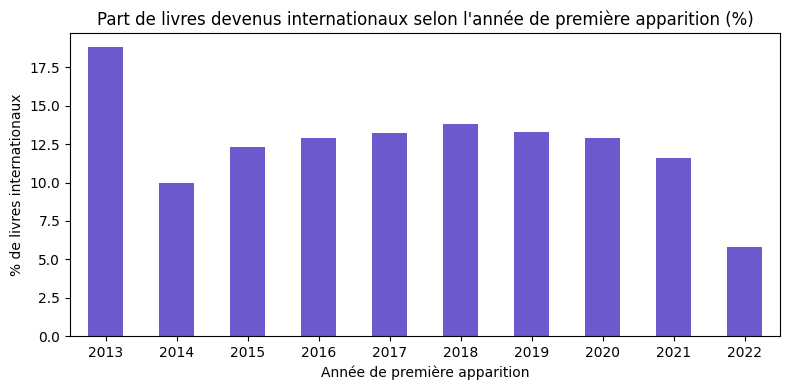

,part_international,nb_livres
annee_premiere,,
2013,18.8,256
2014,10.0,462
2015,12.3,432
2016,12.9,426
2017,13.2,395
2018,13.8,370
2019,13.3,375
2020,12.9,365
2021,11.6,353


In [70]:
livres["annee_premiere"] = livres["date"].dt.year
par_annee = livres.groupby("annee_premiere")["international"].agg(part_international="mean", nb_livres="size")
par_annee["part_international"] = (par_annee["part_international"] * 100).round(1)
ax = par_annee["part_international"].plot(kind="bar", figsize=(8, 4), color="slateblue")
ax.set_title("Part de livres devenus internationaux selon l'année de première apparition (%)")
ax.set_xlabel("Année de première apparition"); ax.set_ylabel("% de livres internationaux")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
par_annee

**Lecture.** De 2014 à 2021, la part de livres internationaux est stable, autour de 12 à 14 %. Les deux années
extrêmes sont biaisées, pour deux raisons opposées :
- **2022 (6 %)** : **censure à droite**. Un livre apparu en octobre 2022 n'a eu que deux mois pour être classé
  ailleurs avant la fin des données. Sa cible vaut 0 non pas parce qu'il est resté national, mais parce qu'on
  ne l'a pas observé assez longtemps. Ces étiquettes 0 sont souvent **fausses**.
- **2013 (19 %)** : **censure à gauche**. La collecte commence en juin 2013 ; un livre « apparu » à cette date
  pouvait être classé depuis des mois, voire déjà diffusé à l'étranger. Ce n'est pas sa vraie première
  apparition.

**Décision :** on garde les livres dont la première apparition est entre **2014 et 2021**. Les lignes de 2013
et 2022 ne sont pas perdues : elles servent à calculer l'historique des auteurs (2013) et à observer la
diffusion des livres de 2021 (2022).

**Conséquence :** un livre apparu fin 2021 n'a qu'environ un an de suivi, contre plusieurs années pour un livre
de 2014. Le taux reste stable en 2021 (11,6 %), donc l'effet est limité.

In [71]:
livres = livres[livres["annee_premiere"].between(2014, 2021)].copy()
print("Livres retenus :", len(livres))
print(f"Part de livres internationaux : {livres['international'].mean():.1%}")

Livres retenus : 3178
Part de livres internationaux : 12.4%


### 4.5 Construction des variables explicatives (*feature engineering*)

**a) Variables de la première apparition**

| Variable | Définition | Intuition |
|---|---|---|
| `pays_premier` | pays de la première apparition | chaque marché a ses propres habitudes (EDA : États-Unis fermé, Allemagne ouvert) |
| `grand_pays_premier` | 1 si ce pays est l'un des 5 pays suivis chaque mois | biais d'échantillonnage : y être repéré ne demande pas le même succès |
| `rang_premier` | rang à la première apparition (1 à 10) | un livre qui entre directement en tête est peut-être plus fort |
| `mois_premier` | mois de la première apparition | saisonnalité (sorties d'automne, fêtes) |
| `genre`, `nb_auteurs`, `collectif` | caractéristiques des auteurs | |
| `nationalite_principale` | première nationalité de l'auteur | |
| `auteur_anglophone` | 1 si un auteur est d'un pays anglophone | l'anglais est la langue qui s'exporte le plus |
| `auteur_local` | 1 si l'auteur a la nationalité du pays de première apparition | un livre déjà classé hors de son pays d'origine a franchi au moins une frontière |
| `pays_edition`, `edition_anglophone` | pays de l'éditeur | |

L'**année** n'est **pas** utilisée comme variable : on teste le modèle sur des années futures,
qu'il n'a jamais vues. Une tendance apprise sur l'année devrait être extrapolée hors de son domaine, ce qui
est peu fiable.

In [72]:
anglophones = {"United States", "United Kingdom", "Ireland", "Australia", "Canada", "New Zealand"}

def contient(liste, ensemble):
    return int(any(n in ensemble for n in liste.split("; ")))

X = pd.DataFrame(index=livres.index)
X["pays_premier"] = livres["country"]
X["grand_pays_premier"] = livres["country"].isin(grands).astype(int)
X["rang_premier"] = livres["rank"]
X["mois_premier"] = livres["date"].dt.month
X["genre"] = livres["genre"]
X["nb_auteurs"] = livres["nb_auteurs"].fillna(1)            # 1 = valeur largement dominante (96 %)
X["collectif"] = (livres["author"] == "[Various]").astype(int)
X["nationalite_principale"] = livres["nationality"].str.split("; ").str[0]
X["auteur_anglophone"] = livres["nationality"].map(lambda n: contient(n, anglophones))
X["auteur_local"] = livres["auteur_local"]                  # NaN si nationalité inconnue
X["pays_edition"] = livres["publication_country"]
X["edition_anglophone"] = livres["publication_country"].map(lambda p: int(p in anglophones))
X.head()

,pays_premier,grand_pays_premier,rang_premier,mois_premier,genre,nb_auteurs,collectif,nationalite_principale,auteur_anglophone,auteur_local,pays_edition,edition_anglophone
livre_id,,,,,,,,,,,,
prideandprejudice | Jane Austen,Australia,0,1,1,femme,1.0,0,United Kingdom,1,0.0,United Kingdom,1
makebeautifuldreams | Massimo Gramellini,Italy,1,1,1,homme,1.0,0,Italy,0,1.0,Italy,0
ripper | Isabel Allende,Spain,1,1,1,femme,1.0,0,Chile,0,0.0,Spain,0
therosieproject | Graeme Simsion,Switzerland,0,1,1,homme,1.0,0,Australia,1,0.0,Australia,1
thebookthief | Markus Zusak,Australia,0,2,1,homme,1.0,0,Australia,1,1.0,United States,1


**b) Variables d'historique (calculées uniquement sur le passé)**

| Variable | Définition |
|---|---|
| `auteur_nb_livres_avant` | nombre de livres différents de l'auteur déjà classés **avant** la première apparition de ce livre |
| `auteur_nb_pays_avant` | nombre de pays où l'auteur a déjà été classé **avant** cette date |
| `auteur_deja_international` | 1 si l'auteur avait déjà été classé dans au moins 2 pays avant cette date |
| `editeur_nb_livres_avant` | nombre de livres différents de l'éditeur déjà classés avant cette date |

**Comment garantir qu'on n'utilise que le passé ?** Pour chaque livre, on ne garde que les lignes de
`dfp` dont la date est **strictement antérieure** à sa première apparition. Les lignes du même mois sont
exclues, car on ne sait pas dans quel ordre les classements d'un même mois ont été publiés.

Les ouvrages collectifs (`[Various]`) n'ont pas d'historique d'auteur : ils partagent tous le même « auteur »,
qui ne désigne pas une personne.

In [73]:
# toutes les lignes de chaque auteur et de chaque éditeur, pour retrouver rapidement leur passé
lignes_auteur = {a: g for a, g in dfp.groupby("author")}
lignes_editeur = {e: g for e, g in dfp.groupby("publisher")}

hist = []
for livre_id, ligne in livres.iterrows():
    date = ligne["date"]
    a = lignes_auteur[ligne["author"]]
    a = a[a["date"] < date]
    e = lignes_editeur[ligne["publisher"]]
    e = e[e["date"] < date]
    collectif = ligne["author"] == "[Various]"
    hist.append({
        "livre_id": livre_id,
        "auteur_nb_livres_avant": 0 if collectif else a["livre_id"].nunique(),
        "auteur_nb_pays_avant": 0 if collectif else a["country"].nunique(),
        "editeur_nb_livres_avant": 0 if ligne["publisher"] == "Inconnu" else e["livre_id"].nunique(),
    })
hist = pd.DataFrame(hist).set_index("livre_id")
hist["auteur_deja_international"] = (hist["auteur_nb_pays_avant"] >= 2).astype(int)
X = X.join(hist)
X[["auteur_nb_livres_avant", "auteur_nb_pays_avant", "editeur_nb_livres_avant", "auteur_deja_international"]].describe().round(2)

,auteur_nb_livres_avant,auteur_nb_pays_avant,editeur_nb_livres_avant,auteur_deja_international
count,3178.00,3178.00,3178.00,3178.00
mean,1.94,1.14,13.94,0.19
std,3.34,2.18,18.42,0.39
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,1.00,0.00
50%,1.00,1.00,7.00,0.00
75%,2.00,1.00,20.00,0.00
max,26.00,20.00,104.00,1.00


In [74]:
# contrôle anti-fuite (ajout) : un exemple vérifié à la main
exemple = livres[livres["author"] == "Paula Hawkins"][["title", "date"]].sort_values("date")
exemple.join(X[["auteur_nb_livres_avant", "auteur_nb_pays_avant"]])

,title,date,auteur_nb_livres_avant,auteur_nb_pays_avant
livre_id,,,,
thegirlonthetrain | Paula Hawkins,The Girl on the Train,2015-01-01,0,0
intothewater | Paula Hawkins,Into the Water,2017-06-01,1,15
aslowfireburning | Paula Hawkins,A Slow Fire Burning,2021-09-01,2,15


**Lecture du contrôle.** Pour le premier livre de Paula Hawkins (*The Girl on the Train*), l'historique vaut
0 : l'autrice n'avait jamais été classée auparavant. Pour son livre suivant, l'historique compte le premier
livre et les pays où il avait déjà été classé **avant** la sortie du second. C'est exactement l'information
dont disposerait un éditeur au moment de la sortie.

### 4.6 Lien entre variables et cible (vérification avant modélisation)
Avant d'entraîner un modèle, on vérifie que certaines variables sont effectivement liées à la cible.

In [75]:
y = livres["international"]
for v in ["auteur_local", "auteur_anglophone", "auteur_deja_international", "grand_pays_premier", "collectif"]:
    t = pd.DataFrame({"x": X[v], "y": y}).groupby("x")["y"].agg(part_international="mean", nb_livres="size")
    t["part_international"] = (t["part_international"] * 100).round(1)
    print(f"--- {v}\n{t}\n")

--- auteur_local
     part_international  nb_livres
x                                 
0.0                23.3       1113
1.0                 6.6       2058

--- auteur_anglophone
   part_international  nb_livres
x                               
0                 6.5       1902
1                21.3       1276

--- auteur_deja_international
   part_international  nb_livres
x                               
0                 7.4       2565
1                33.4        613

--- grand_pays_premier
   part_international  nb_livres
x                               
0                14.0       1191
1                11.5       1987

--- collectif
   part_international  nb_livres
x                               
0                12.5       3164
1                 0.0         14



**Lecture.** Plusieurs variables sont très discriminantes :
- un livre d'auteur **non local** (déjà classé hors du pays de l'auteur) devient beaucoup plus souvent
  international qu'un livre d'auteur local ;
- un auteur **anglophone**, et plus encore un auteur **déjà international**, augmentent fortement la probabilité.

C'est encourageant pour le modèle, mais ces variables sont aussi **liées entre elles** (un auteur américain
classé en Allemagne est à la fois anglophone et non local). Le modèle devra démêler leurs effets.

### 4.7 Distribution des variables numériques et transformation logarithmique

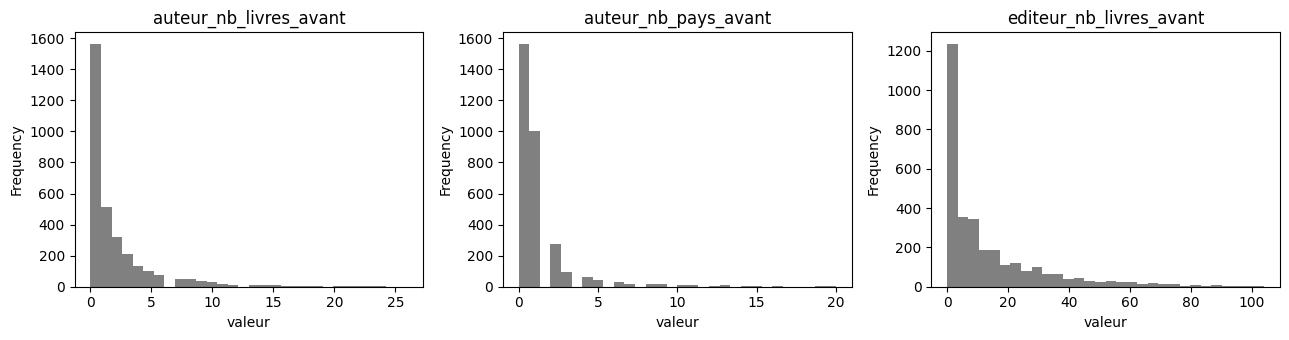

Asymétrie (skewness) :
auteur_nb_livres_avant     2.91
auteur_nb_pays_avant       3.97
editeur_nb_livres_avant    1.96
dtype: float64


In [76]:
num_hist = ["auteur_nb_livres_avant", "auteur_nb_pays_avant", "editeur_nb_livres_avant"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, v in zip(axes, num_hist):
    X[v].plot(kind="hist", bins=30, ax=ax, color="gray")
    ax.set_title(v); ax.set_xlabel("valeur")
plt.tight_layout(); plt.show()
print("Asymétrie (skewness) :")
print(X[num_hist].skew().round(2))

**Lecture.** Les trois variables d'historique sont très **asymétriques** : la plupart des livres ont un
historique nul ou faible, et quelques auteurs ou éditeurs très prolifiques ont des valeurs élevées
(asymétrie largement supérieure à 1).

**Conséquence et choix :** pour un modèle linéaire comme la régression logistique, ces valeurs extrêmes pèsent
trop lourd. On applique `log(1 + x)` (`np.log1p`), qui :
- compresse les grandes valeurs (passer de 0 à 5 livres compte plus que passer de 50 à 55) ;
- garde 0 à 0 (d'où le `+1`, car `log(0)` n'existe pas).

Les modèles à base d'arbres n'en ont pas besoin, car ils ne regardent que l'ordre des valeurs, mais la
transformation ne leur nuit pas.

### 4.8 Séparation entraînement / test : une séparation **temporelle**

**Choix :** entraînement sur les livres apparus de **2014 à 2019**, test sur ceux apparus en **2020 et 2021**.

| Option | Avantage | Inconvénient |
|---|---|---|
| Séparation aléatoire (80 / 20) | simple ; classes bien réparties | le modèle apprend sur des livres de 2021 et est testé sur des livres de 2015 : il « voit le futur », ce qui surestime la performance |
| **Séparation temporelle** | reproduit l'usage réel : prédire les nouveaux livres à partir des anciens | si le marché change, la performance baisse ; c'est justement ce qu'on veut mesurer |

On garde aussi la séparation par **livre** : un même livre n'est jamais à la fois dans l'entraînement et dans
le test, puisqu'il n'y a qu'une ligne par livre.

In [77]:
annee = livres["annee_premiere"]
X_train, X_test = X[annee <= 2019], X[annee >= 2020]
y_train, y_test = y[annee <= 2019], y[annee >= 2020]

print("Entraînement :", X_train.shape, f"| part internationale : {y_train.mean():.1%}")
print("Test         :", X_test.shape, f"| part internationale : {y_test.mean():.1%}")

Entraînement : (2460, 16) | part internationale : 12.5%
Test         : (718, 16) | part internationale : 12.3%


**Lecture.** Environ 2 400 livres pour l'entraînement et 700 pour le test, avec une part de livres internationaux
comparable (environ 13 % et 12 %). Les **classes sont déséquilibrées** : un modèle qui répondrait toujours
« non international » aurait environ 88 % d'exactitude (*accuracy*) sans rien avoir appris. Il faudra donc
d'autres métriques (section 6).

### 4.9 Encodage et mise à l'échelle : le `ColumnTransformer`

Les modèles de scikit-learn n'acceptent que des **nombres**. On définit une chaîne de transformations par type
de colonne :

| Colonnes | Transformation | Pourquoi |
|---|---|---|
| catégorielles (`pays_premier`, `genre`, `nationalite_principale`, `pays_edition`) | **One-Hot Encoding** : une colonne 0/1 par catégorie | ce sont des catégories sans ordre ; les numéroter (France = 1, Italie = 2…) inventerait un ordre qui n'existe pas |
| | `min_frequency=20` : les catégories qui ont moins de 20 livres dans l'entraînement sont regroupées en une catégorie « rare » | évite des dizaines de colonnes avec 1 ou 2 livres, sur lesquelles le modèle apprendrait du bruit (sur-apprentissage) |
| | `handle_unknown="infrequent_if_exist"` | un pays jamais vu à l'entraînement est traité comme « rare » au lieu de provoquer une erreur |
| historiques (comptages) | imputation (0), puis `log1p`, puis standardisation | asymétrie (4.7) |
| `rang_premier`, `mois_premier`, `nb_auteurs` | standardisation | |
| binaires (`auteur_local`…) | imputation de `auteur_local` par sa valeur la plus fréquente + indicateur « valeur manquante » | quelques livres ont une nationalité inconnue |

La **standardisation** (`StandardScaler`) ramène chaque variable à une moyenne de 0 et un écart-type de 1.
Sinon, une variable aux grandes valeurs (nombre de livres d'un éditeur : jusqu'à plusieurs dizaines) dominerait
une variable binaire dans une régression logistique.

**Règle d'or : on ajuste (`fit`) ces transformations sur l'entraînement uniquement.** Les catégories retenues,
les moyennes et les écarts-types sont calculés sur `X_train`, puis appliqués tels quels à `X_test`. Si on les
calculait sur toutes les données, des informations du test passeraient dans l'entraînement : c'est une autre
forme de fuite de données. En pratique, le `ColumnTransformer` sera placé dans un **`Pipeline`** avec le
modèle (section 5), ce qui garantit automatiquement ce comportement, y compris pendant la validation croisée.

In [78]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

cat_cols = ["pays_premier", "genre", "nationalite_principale", "pays_edition"]
log_cols = ["auteur_nb_livres_avant", "auteur_nb_pays_avant", "editeur_nb_livres_avant"]
num_cols = ["rang_premier", "mois_premier", "nb_auteurs"]
bin_cols = ["grand_pays_premier", "collectif", "auteur_anglophone", "auteur_local",
            "edition_anglophone", "auteur_deja_international"]

preprocesseur = ColumnTransformer([
    ("cat", OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist", sparse_output=False), cat_cols),
    ("log", make_pipeline(SimpleImputer(strategy="constant", fill_value=0),
                          FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                          StandardScaler()), log_cols),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("bin", SimpleImputer(strategy="most_frequent", add_indicator=True), bin_cols),
])

# démonstration : ajustement sur l'entraînement seul, puis application au test
Xt_train = preprocesseur.fit_transform(X_train)
Xt_test = preprocesseur.transform(X_test)
noms = preprocesseur.get_feature_names_out()
print("Colonnes avant transformation :", X_train.shape[1], "| après :", Xt_train.shape[1])
print("Train :", Xt_train.shape, "| Test :", Xt_test.shape)
pd.DataFrame(Xt_train, columns=noms, index=X_train.index).head()

Colonnes avant transformation : 16 | après : 84
Train : (2460, 84) | Test : (718, 84)


,cat__pays_premier_Argentina,cat__pays_premier_Australia,cat__pays_premier_Austria,cat__pays_premier_Brazil,cat__pays_premier_Canada,cat__pays_premier_China,cat__pays_premier_Finland,cat__pays_premier_France,cat__pays_premier_Germany,cat__pays_premier_Greece,...,num__rang_premier,num__mois_premier,num__nb_auteurs,bin__grand_pays_premier,bin__collectif,bin__auteur_anglophone,bin__auteur_local,bin__edition_anglophone,bin__auteur_deja_international,bin__missingindicator_auteur_local
livre_id,,,,,,,,,,,,,,,,,,,,,
prideandprejudice | Jane Austen,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-1.567110,-1.587354,-0.189427,0.0,0.0,1.0,0.0,1.0,0.0,0.0
makebeautifuldreams | Massimo Gramellini,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-1.567110,-1.587354,-0.189427,1.0,0.0,0.0,1.0,0.0,0.0,0.0
ripper | Isabel Allende,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-1.567110,-1.587354,-0.189427,1.0,0.0,0.0,0.0,0.0,0.0,0.0
therosieproject | Graeme Simsion,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-1.567110,-1.587354,-0.189427,0.0,0.0,1.0,0.0,1.0,0.0,0.0
thebookthief | Markus Zusak,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-1.220211,-1.587354,-0.189427,0.0,0.0,1.0,1.0,1.0,0.0,0.0


In [79]:
# quelles catégories ont été conservées, et lesquelles regroupées en "rare" ?
encodeur = preprocesseur.named_transformers_["cat"]
for col, cats, rares in zip(cat_cols, encodeur.categories_, encodeur.infrequent_categories_):
    nb_rares = 0 if rares is None else len(rares)
    print(f"{col:24s} : {len(cats) - nb_rares} catégories conservées, {nb_rares} regroupées en 'rare'")

pays_premier             : 29 catégories conservées, 13 regroupées en 'rare'
genre                    : 3 catégories conservées, 1 regroupées en 'rare'
nationalite_principale   : 19 catégories conservées, 50 regroupées en 'rare'
pays_edition             : 16 catégories conservées, 29 regroupées en 'rare'


**Lecture.** Les quatre variables catégorielles comptent des dizaines de modalités, mais seules celles qui
ont au moins 20 livres dans l'entraînement reçoivent leur propre colonne. Toutes les autres sont regroupées.
Le jeu de données final est entièrement numérique, sans valeur manquante, et prêt pour la modélisation.

### 4.10 Bilan de la transformation

| Étape | Choix | Raison |
|---|---|---|
| Unité d'analyse | une ligne par livre | la question porte sur le destin d'un livre, pas d'une apparition |
| Cible | classé dans ≥ 2 pays | mesure de succès disponible, sans chiffres de ventes |
| Variables | première apparition + historique **strictement passé** | éviter la fuite de données |
| Période | premières apparitions 2014–2021 | éviter la censure à gauche (2013) et à droite (2022) |
| Séparation | temporelle : 2014–2019 / 2020–2021 | reproduire l'usage réel |
| Encodage | One-Hot avec regroupement des catégories rares | catégories sans ordre ; limiter le bruit |
| Échelle | `log1p` pour les comptages, puis standardisation | asymétrie ; comparabilité des variables |
| Ajustement | sur l'entraînement uniquement, dans un `Pipeline` | éviter la fuite de données du test vers l'entraînement |

## 5. Machine Learning

**Démarche.**
1. Un **modèle de référence** (*baseline*), qui ne regarde pas les variables : tout modèle doit faire mieux.
2. Trois familles de modèles, de la plus simple à la plus flexible.
3. Une comparaison par **validation croisée temporelle** sur l'entraînement uniquement : le test reste
   intouché jusqu'à l'évaluation finale.
4. Le réglage des hyperparamètres du meilleur modèle.

Chaque modèle est un **`Pipeline`** = `preprocesseur` (section 4.9) + classifieur. Ainsi, l'encodage et la
standardisation sont réajustés **dans chaque pli** de la validation croisée, sur la partie d'entraînement du
pli uniquement. Sans cela, la validation croisée serait faussée par une fuite de données.

### 5.1 Les modèles

| Modèle | Principe | Pourquoi l'essayer |
|---|---|---|
| `DummyClassifier` | prédit toujours la classe majoritaire (« non international ») | référence minimale : mesure ce qu'on obtient **sans** apprendre |
| Régression logistique | modèle **linéaire** : probabilité = fonction sigmoïde d'une somme pondérée des variables | simple, rapide, **interprétable** (chaque coefficient dit dans quel sens une variable pousse) |
| Forêt aléatoire (*Random Forest*) | moyenne de nombreux arbres de décision, chacun appris sur un échantillon différent | capte les **interactions** (par exemple : anglophone **et** non local) et les effets non linéaires |
| Gradient Boosting (`HistGradientBoostingClassifier`) | arbres construits **l'un après l'autre**, chacun corrigeant les erreurs des précédents | souvent le plus performant sur des données tabulaires |

**Déséquilibre des classes : `class_weight="balanced"`.** Avec 12,5 % de livres internationaux, un modèle
qui minimise simplement ses erreurs apprend à répondre presque toujours « non ». L'option
`class_weight="balanced"` donne à chaque exemple de la classe rare un poids inversement proportionnel à sa
fréquence, ici environ 7 fois plus qu'un exemple de la classe majoritaire. Une erreur sur un livre
international coûte donc autant, au total, que les erreurs sur les livres nationaux.

| Alternative | Pourquoi on ne la retient pas |
|---|---|
| Sous-échantillonnage (supprimer des livres nationaux) | perd des données alors qu'on n'en a déjà que 2 460 |
| Sur-échantillonnage (créer des livres internationaux artificiels) | crée de faux exemples, et doit être fait à l'intérieur de chaque pli de validation, sinon il fuit ; les poids de classes donnent un effet comparable plus simplement |

In [80]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone

modeles = {
    "Référence (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                              class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
}
pipelines = {nom: Pipeline([("preparation", clone(preprocesseur)), ("modele", m)])
             for nom, m in modeles.items()}

### 5.2 Choix des métriques

| Métrique | Définition | Intérêt ici |
|---|---|---|
| *Accuracy* (exactitude) | part de prédictions correctes | **trompeuse** : 87,5 % en prédisant toujours « non » |
| Précision | parmi les livres prédits internationaux, part qui le sont vraiment | coût d'une fausse alerte (traduire un livre qui ne se vendra pas) |
| Rappel (*recall*) | parmi les livres vraiment internationaux, part détectée | coût d'une occasion manquée |
| F1 | moyenne harmonique de la précision et du rappel | résume les deux ; nulle si le modèle ne détecte rien |
| ROC-AUC | probabilité qu'un livre international reçoive un score plus élevé qu'un livre national | qualité du **classement** des livres, indépendante du seuil ; 0,5 = hasard |
| **PR-AUC** (*average precision*) | aire sous la courbe précision-rappel | **métrique principale** : adaptée aux classes rares ; le hasard vaut la proportion de la classe rare (0,125), et non 0,5 |

Les métriques au seuil (précision, rappel, F1) dépendent du seuil de décision, 0,5 par défaut ; ROC-AUC et
PR-AUC évaluent le classement par probabilité sur tous les seuils. Le choix du seuil est traité à
l'évaluation (section 6.3).

### 5.3 Validation croisée temporelle

La validation croisée estime la performance **sans toucher au test** : on découpe l'entraînement en plusieurs
plis, on apprend sur une partie et on évalue sur l'autre, plusieurs fois.

Pour rester cohérent avec la séparation temporelle (section 4.8), on utilise `TimeSeriesSplit` : les livres
sont triés par date, et chaque pli **apprend sur le passé et valide sur la période suivante**, jamais
l'inverse. Une validation croisée aléatoire (`StratifiedKFold`) ferait de nouveau « voir le futur » au modèle.

In [81]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

ordre = livres.loc[X_train.index, "date"].sort_values().index      # tri chronologique
X_train, y_train = X_train.loc[ordre], y_train.loc[ordre]

cv = TimeSeriesSplit(n_splits=5)
for i, (tr, va) in enumerate(cv.split(X_train)):
    d = livres.loc[X_train.index, "date"]
    print(f"Pli {i+1} : apprentissage {d.iloc[tr].min():%Y-%m} → {d.iloc[tr].max():%Y-%m} ({len(tr)} livres) | "
          f"validation {d.iloc[va].min():%Y-%m} → {d.iloc[va].max():%Y-%m} ({len(va)} livres, "
          f"{y_train.iloc[va].mean():.0%} internationaux)")

Pli 1 : apprentissage 2014-01 → 2014-11 (410 livres) | validation 2014-11 → 2015-10 (410 livres, 11% internationaux)
Pli 2 : apprentissage 2014-01 → 2015-10 (820 livres) | validation 2015-10 → 2016-10 (410 livres, 12% internationaux)
Pli 3 : apprentissage 2014-01 → 2016-10 (1230 livres) | validation 2016-10 → 2017-10 (410 livres, 13% internationaux)
Pli 4 : apprentissage 2014-01 → 2017-10 (1640 livres) | validation 2017-10 → 2018-11 (410 livres, 15% internationaux)
Pli 5 : apprentissage 2014-01 → 2018-11 (2050 livres) | validation 2018-11 → 2019-12 (410 livres, 14% internationaux)


In [82]:
scores = ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
resultats_cv = {}
for nom, pipe in pipelines.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scores)
    resultats_cv[nom] = {m: r[f"test_{m}"].mean() for m in scores} | {"PR-AUC écart-type": r["test_average_precision"].std()}

tableau_cv = pd.DataFrame(resultats_cv).T.rename(columns={"average_precision": "PR-AUC", "roc_auc": "ROC-AUC"})
tableau_cv.round(3)

,accuracy,balanced_accuracy,precision,recall,f1,ROC-AUC,PR-AUC,PR-AUC écart-type
Référence (classe majoritaire),0.870,0.500,0.000,0.000,0.000,0.500,0.130,0.013
Régression logistique,0.734,0.710,0.280,0.678,0.396,0.771,0.430,0.109
Forêt aléatoire,0.798,0.680,0.324,0.522,0.399,0.771,0.409,0.110
Gradient Boosting,0.826,0.653,0.351,0.420,0.379,0.715,0.369,0.116


**Lecture.**
- La **référence** a une *accuracy* élevée (environ 0,87) mais une précision, un rappel et un F1 **nuls** :
  elle ne détecte aucun livre international. C'est la démonstration que l'accuracy est trompeuse ici. Sa
  ROC-AUC vaut 0,5 et sa PR-AUC la proportion de livres internationaux : c'est le niveau du hasard.
- Les trois modèles appris font **nettement mieux que le hasard** : PR-AUC de 0,37 à 0,43, soit environ
  trois fois celle de la référence (0,13), et ROC-AUC de 0,72 à 0,78. Les variables construites contiennent
  donc une vraie information sur l'avenir international d'un livre.
- La régression logistique et la forêt aléatoire ont un **rappel élevé (0,64 à 0,68) et une précision plus
  faible (0,28)** : grâce à `class_weight="balanced"`, elles signalent beaucoup de livres pour en rater peu.
  Cet équilibre se règle avec le seuil (section 6.3). Le Gradient Boosting, avec ses réglages par défaut,
  est plus prudent (rappel de 0,42) et moins bon en PR-AUC.
- L'écart-type de la PR-AUC entre plis (environ 0,11) est grand devant les écarts entre la régression
  logistique et la forêt aléatoire : ces deux modèles ne sont pas significativement différents. La régression
  logistique, la plus simple, obtient le meilleur score moyen.

### 5.4 Réglage des hyperparamètres

Les **hyperparamètres** sont les réglages d'un modèle fixés avant l'apprentissage (profondeur des arbres,
force de la régularisation…). On les choisit par **recherche en grille** (`GridSearchCV`) : chaque combinaison
est évaluée par la même validation croisée temporelle, et on garde celle qui maximise la PR-AUC.

On règle deux modèles :
- la **régression logistique** : `C` est l'inverse de la force de régularisation. Un petit `C` force des
  coefficients petits, donc un modèle plus simple, moins sujet au sur-apprentissage ;
- le **Gradient Boosting** : `learning_rate` (taille de chaque correction), `max_depth` (complexité de chaque
  arbre) et `max_iter` (nombre d'arbres).

In [83]:
from sklearn.model_selection import GridSearchCV

grilles = {
    "Régression logistique": {"modele__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    "Gradient Boosting": {"modele__learning_rate": [0.03, 0.1],
                          "modele__max_depth": [2, 3, None],
                          "modele__max_iter": [100, 300]},
}
meilleurs = {}
for nom, grille in grilles.items():
    recherche = GridSearchCV(pipelines[nom], grille, cv=cv, scoring="average_precision", n_jobs=-1)
    recherche.fit(X_train, y_train)
    meilleurs[nom] = recherche.best_estimator_
    print(f"{nom} : meilleurs hyperparamètres {recherche.best_params_} | PR-AUC (validation croisée) = {recherche.best_score_:.3f}")

Régression logistique : meilleurs hyperparamètres {'modele__C': 0.1} | PR-AUC (validation croisée) = 0.437
Gradient Boosting : meilleurs hyperparamètres {'modele__learning_rate': 0.03, 'modele__max_depth': 3, 'modele__max_iter': 100} | PR-AUC (validation croisée) = 0.419


**Lecture.**
- **Régression logistique :** le meilleur `C` vaut 0,1, une régularisation assez forte ; le gain est faible
  (PR-AUC de 0,430 à 0,437).
- **Gradient Boosting :** le gain est net (de 0,369 à 0,419), avec un apprentissage lent (`learning_rate`
  0,03), des arbres peu profonds (`max_depth` 3) et peu d'arbres (100). C'est la configuration **la plus
  simple** de la grille.

Les deux réglages vont dans le même sens : les données récompensent des **modèles simples**. Avec 2 460 livres
et un signal assez linéaire, un modèle trop complexe apprendrait du bruit (sur-apprentissage).

La forêt aléatoire n'est pas réglée : ses performances en 5.3 étaient comparables aux deux autres, et
l'objectif est de comparer deux approches bien différentes (linéaire et arbres boostés). Elle est quand même
gardée pour l'évaluation finale.

In [84]:
modeles_finaux = {
    "Référence (classe majoritaire)": pipelines["Référence (classe majoritaire)"],
    "Régression logistique": meilleurs["Régression logistique"],
    "Forêt aléatoire": pipelines["Forêt aléatoire"],
    "Gradient Boosting": meilleurs["Gradient Boosting"],
}
for nom, m in modeles_finaux.items():
    m.fit(X_train, y_train)          # réentraînement sur tout l'entraînement (2014-2019)
print("Modèles entraînés :", list(modeles_finaux))

Modèles entraînés : ['Référence (classe majoritaire)', 'Régression logistique', 'Forêt aléatoire', 'Gradient Boosting']


## 6. Évaluation

Les modèles sont maintenant évalués **une seule fois** sur le jeu de test (livres apparus en 2020-2021),
qu'ils n'ont jamais vu. Si l'on comparait de nombreux modèles sur le test et qu'on gardait le meilleur, le
test deviendrait lui aussi un jeu de réglage, et son score serait optimiste.

### 6.1 Scores sur le jeu de test

In [85]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)

def evaluer(y_vrai, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int)
    return {"accuracy": accuracy_score(y_vrai, pred),
            "balanced_accuracy": balanced_accuracy_score(y_vrai, pred),
            "précision": precision_score(y_vrai, pred, zero_division=0),
            "rappel": recall_score(y_vrai, pred),
            "F1": f1_score(y_vrai, pred),
            "ROC-AUC": roc_auc_score(y_vrai, proba),
            "PR-AUC": average_precision_score(y_vrai, proba)}

probas_test = {nom: m.predict_proba(X_test)[:, 1] for nom, m in modeles_finaux.items()}
tableau_test = pd.DataFrame({nom: evaluer(y_test, p) for nom, p in probas_test.items()}).T
tableau_test.round(3)

,accuracy,balanced_accuracy,précision,rappel,F1,ROC-AUC,PR-AUC
Référence (classe majoritaire),0.877,0.500,0.000,0.000,0.000,0.500,0.123
Régression logistique,0.721,0.778,0.286,0.852,0.429,0.851,0.492
Forêt aléatoire,0.784,0.750,0.325,0.705,0.444,0.842,0.447
Gradient Boosting,0.702,0.752,0.267,0.818,0.402,0.830,0.426


**Lecture.** Sur des livres de 2020-2021 jamais vus, les scores sont même **un peu meilleurs** qu'en
validation croisée (PR-AUC 0,49 contre 0,44 ; ROC-AUC 0,85 contre 0,77). Deux raisons :
- le modèle final apprend sur les 2 460 livres de l'entraînement, alors que dans les premiers plis de la
  validation croisée il n'en voyait que 410 à 2 050 ;
- la validation croisée variait beaucoup d'un pli à l'autre (écart-type de 0,11) : l'écart reste dans
  cette marge.

Le modèle **généralise donc au futur**.

**Nous retenons la régression logistique** : elle obtient les meilleurs scores en validation croisée comme sur
le test, c'est le modèle le plus simple, et le seul dont on peut lire directement l'effet de chaque variable. Même à performance égale, on l'aurait choisie, car entre deux modèles
équivalents, on préfère le plus simple.

In [86]:
nom_retenu = "Régression logistique"
modele_retenu = modeles_finaux[nom_retenu]
proba_retenu = probas_test[nom_retenu]

### 6.2 Courbes ROC et précision-rappel

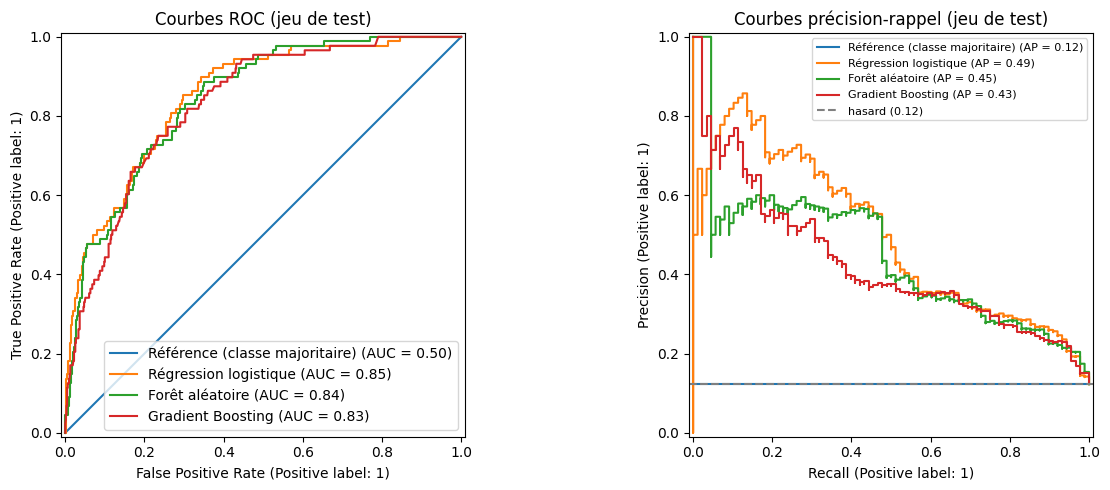

In [87]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nom, p in probas_test.items():
    RocCurveDisplay.from_predictions(y_test, p, name=nom, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=nom, ax=axes[1])
axes[0].set_title("Courbes ROC (jeu de test)")
axes[1].axhline(y_test.mean(), ls="--", color="gray", label=f"hasard ({y_test.mean():.2f})")
axes[1].set_title("Courbes précision-rappel (jeu de test)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture des courbes.**
- **ROC** (gauche) : l'axe horizontal est le taux de faux positifs (livres nationaux signalés à tort),
  l'axe vertical le taux de vrais positifs (rappel). La diagonale correspond au hasard (la référence).
  Les trois modèles s'en écartent nettement et se superposent presque : ils classent les livres de façon
  très similaire.
- **Précision-rappel** (droite) : la ligne pointillée est le niveau du hasard (12 % de livres
  internationaux). Pour un faible rappel (on ne signale que les livres les plus sûrs), la précision est
  élevée : les livres auxquels le modèle donne les plus fortes probabilités sont très souvent réellement
  internationaux. Quand on veut en détecter davantage, la précision baisse vite : beaucoup de livres
  internationaux ressemblent, au moment de leur sortie, à des livres qui resteront nationaux.

### 6.3 Choix du seuil de décision

Le modèle donne une **probabilité** ; la décision « international / national » dépend d'un **seuil**. Le seuil
par défaut, 0,5, n'a rien de naturel ici, surtout avec `class_weight="balanced"`, qui gonfle les probabilités
de la classe rare.

**Méthode.** Le seuil ne doit **pas** être choisi sur le test (ce serait encore une fuite). On le choisit sur
les **prédictions de validation croisée** de l'entraînement : pour chaque pli temporel, le modèle prédit la
période suivante, et on cherche le seuil qui maximise le F1 sur ces prédictions. On applique ensuite ce seuil
fixe au test.

In [88]:
from sklearn.metrics import precision_recall_curve

probas_val, y_val = [], []
for tr, va in cv.split(X_train):
    m = clone(modele_retenu).fit(X_train.iloc[tr], y_train.iloc[tr])
    probas_val.append(m.predict_proba(X_train.iloc[va])[:, 1])
    y_val.append(y_train.iloc[va])
probas_val, y_val = np.concatenate(probas_val), np.concatenate(y_val)

prec, rapp, seuils = precision_recall_curve(y_val, probas_val)
f1s = 2 * prec[:-1] * rapp[:-1] / (prec[:-1] + rapp[:-1] + 1e-12)
seuil_optimal = seuils[np.argmax(f1s)]
print(f"Seuil qui maximise le F1 en validation : {seuil_optimal:.3f}")

comparaison_seuils = pd.DataFrame({"seuil 0,5": evaluer(y_test, proba_retenu, 0.5),
                                   f"seuil {seuil_optimal:.2f}": evaluer(y_test, proba_retenu, seuil_optimal)}).T
comparaison_seuils.round(3)

Seuil qui maximise le F1 en validation : 0.624


,accuracy,balanced_accuracy,précision,rappel,F1,ROC-AUC,PR-AUC
"seuil 0,5",0.721,0.778,0.286,0.852,0.429,0.851,0.492
seuil 0.62,0.815,0.733,0.355,0.625,0.453,0.851,0.492


**Lecture.** Le seuil choisi en validation est **plus élevé** que 0,5. Avec lui, le modèle signale moins de
livres : la précision augmente et le rappel diminue, pour un F1 meilleur sur le test. Le choix du seuil est
une **décision métier** : un éditeur qui veut ne rater aucun futur succès (pour acheter les droits tôt)
choisira un seuil bas ; un éditeur qui veut limiter les traductions coûteuses et risquées choisira un seuil
haut. Les ROC-AUC et PR-AUC, elles, ne changent pas : elles ne dépendent pas du seuil.

### 6.4 Matrice de confusion

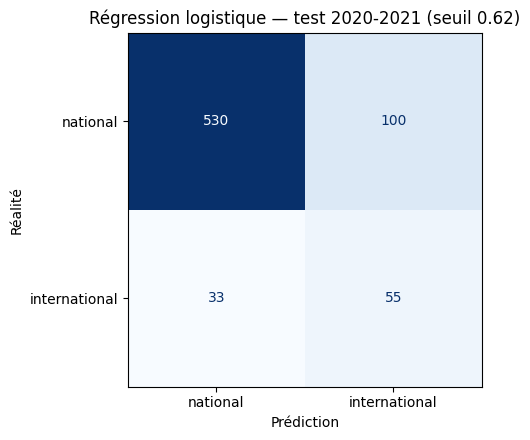

               precision    recall  f1-score   support

     national      0.941     0.841     0.889       630
international      0.355     0.625     0.453        88

     accuracy                          0.815       718
    macro avg      0.648     0.733     0.671       718
 weighted avg      0.869     0.815     0.835       718



In [89]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

pred_retenu = (proba_retenu >= seuil_optimal).astype(int)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_retenu, display_labels=["national", "international"],
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"{nom_retenu} — test 2020-2021 (seuil {seuil_optimal:.2f})")
ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité")
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred_retenu, target_names=["national", "international"], digits=3))

**Lecture de la matrice.**
- **Diagonale** (vrais négatifs en haut à gauche, vrais positifs en bas à droite) : les prédictions correctes.
- **En haut à droite** (faux positifs) : des livres restés nationaux que le modèle croyait internationaux.
- **En bas à gauche** (faux négatifs) : des succès internationaux que le modèle n'a pas vus venir.

Le modèle reconnaît très bien les livres qui resteront nationaux : 84 % d'entre eux sont bien classés, et
quand il prédit « national », il a raison dans 94 % des cas. Pour la classe internationale, il détecte
55 des 88 succès internationaux (rappel de 62 %), au prix d'environ **deux fausses alertes pour un succès
détecté** (précision de 36 %). C'est le prix à payer pour une classe rare et difficile à prévoir, mais c'est
trois fois mieux qu'un tirage au hasard, qui aurait une précision de 12 %. Le
`classification_report` donne les mêmes informations en chiffres pour chaque classe ; la ligne
`macro avg` fait la moyenne des deux classes sans tenir compte de leur taille, ce qui la rend plus exigeante
que l'accuracy.

### 6.5 Interprétation du modèle

**a) Coefficients de la régression logistique.** Les variables numériques étant standardisées, la taille d'un
coefficient mesure l'importance de la variable, et son signe le sens de l'effet. `exp(coefficient)` est un
**rapport de cotes** (*odds ratio*) : la cote de devenir international est multipliée par ce nombre quand la
variable augmente d'un écart-type (ou passe de 0 à 1 pour une variable binaire).

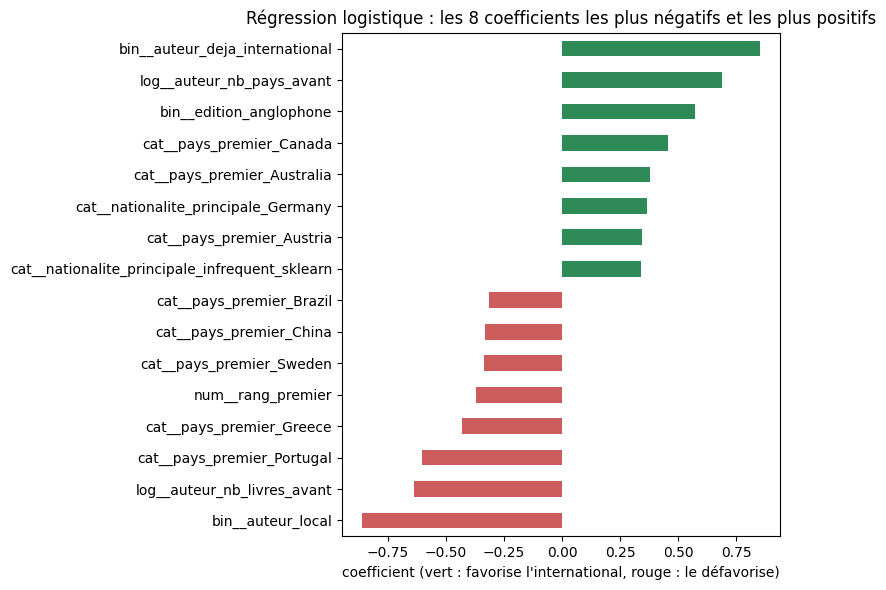

,coefficient,rapport de cotes
bin__auteur_deja_international,0.85,2.35
log__auteur_nb_pays_avant,0.69,1.99
bin__edition_anglophone,0.57,1.78
cat__pays_premier_Canada,0.45,1.58
cat__pays_premier_Australia,0.38,1.46
cat__nationalite_principale_Germany,0.37,1.44
cat__pays_premier_Austria,0.34,1.41
cat__nationalite_principale_infrequent_sklearn,0.34,1.41
cat__pays_premier_Brazil,-0.31,0.73
cat__pays_premier_China,-0.33,0.72


In [90]:
noms_vars = modele_retenu.named_steps["preparation"].get_feature_names_out()
coefs = pd.Series(modele_retenu.named_steps["modele"].coef_[0], index=noms_vars)
coefs_tries = pd.concat([coefs.nsmallest(8), coefs.nlargest(8)]).sort_values()

ax = coefs_tries.plot(kind="barh", figsize=(8, 6),
                      color=["indianred" if c < 0 else "seagreen" for c in coefs_tries])
ax.set_title("Régression logistique : les 8 coefficients les plus négatifs et les plus positifs")
ax.set_xlabel("coefficient (vert : favorise l'international, rouge : le défavorise)")
plt.tight_layout(); plt.show()
pd.DataFrame({"coefficient": coefs_tries, "rapport de cotes": np.exp(coefs_tries)}).round(2).iloc[::-1]

**Lecture.** Les effets les plus forts confirment l'EDA et la section 4.6, et ont un sens commercial :
- **l'historique international de l'auteur** est l'effet positif le plus fort (`auteur_deja_international`,
  rapport de cotes 2,35, et `auteur_nb_pays_avant`, 1,99) : un auteur dont les livres précédents se sont déjà
  exportés a des éditeurs étrangers et un public qui l'attend ;
- un **éditeur anglophone** (1,78) favorise l'exportation ;
- **`auteur_local`** est l'effet négatif le plus fort (0,42) : un livre d'abord classé dans le pays de son
  auteur n'a encore franchi aucune frontière, au contraire d'un livre d'auteur étranger ;
- **`rang_premier`** est négatif : plus le rang d'entrée est mauvais (grand numéro), moins le livre devient
  international ;
- **`auteur_nb_livres_avant` est négatif**, ce qui peut surprendre. Il faut le lire **à nombre de pays
  égal** : un auteur qui a déjà publié beaucoup de best-sellers, mais dans peu de pays, est un auteur à succès
  **national** (comme Andrea Camilleri en Italie), dont le nouveau livre restera probablement national lui aussi ;
- les autres coefficients concernent le **pays de première apparition** : apparaître d'abord dans un pays où
  les classements accueillent beaucoup de livres étrangers (Canada, Australie, Autriche) est associé à
  l'international, alors que le Portugal, la Grèce, la Suède ou la Chine sont associés à des succès plus locaux.

**Prudence.** Ces coefficients décrivent des **associations**, pas des causes, et les variables sont
corrélées entre elles (section 4.6) : le modèle répartit l'effet commun entre elles, ce qui rend l'effet
d'une variable isolée difficile à interpréter seul.

**b) Importance par permutation.** Méthode indépendante du modèle : on mélange au hasard les valeurs d'une
variable dans le jeu de test et on mesure la baisse de PR-AUC. Plus la baisse est forte, plus le modèle
dépend de cette variable. Elle porte sur les **16 variables d'origine**, et non sur les 84 colonnes encodées.

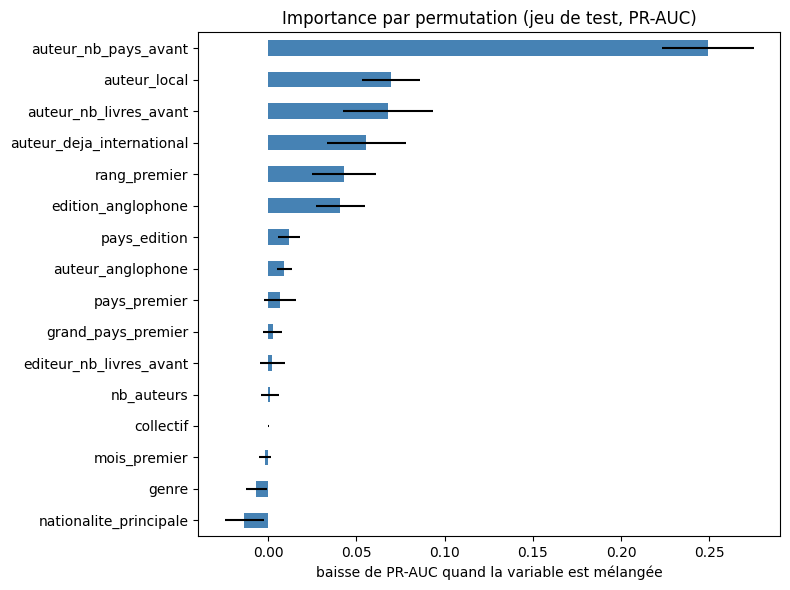

,baisse de PR-AUC,écart-type
auteur_nb_pays_avant,0.249,0.026
auteur_local,0.070,0.016
auteur_nb_livres_avant,0.068,0.026
auteur_deja_international,0.056,0.022
rang_premier,0.043,0.018
edition_anglophone,0.041,0.014
pays_edition,0.012,0.006
auteur_anglophone,0.009,0.004
pays_premier,0.007,0.009
grand_pays_premier,0.002,0.005


In [91]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(modele_retenu, X_test, y_test, scoring="average_precision",
                             n_repeats=20, random_state=42, n_jobs=-1)
importance = pd.DataFrame({"baisse de PR-AUC": imp.importances_mean, "écart-type": imp.importances_std},
                          index=X_test.columns).sort_values("baisse de PR-AUC")
ax = importance["baisse de PR-AUC"].plot(kind="barh", xerr=importance["écart-type"], figsize=(8, 6), color="steelblue")
ax.set_title("Importance par permutation (jeu de test, PR-AUC)")
ax.set_xlabel("baisse de PR-AUC quand la variable est mélangée")
plt.tight_layout(); plt.show()
importance.iloc[::-1].round(3)

**Lecture.**
- Une variable domine très largement : **`auteur_nb_pays_avant`** (baisse de PR-AUC de 0,25 quand on la
  mélange). Savoir dans combien de pays l'auteur a déjà été classé est, de loin, la meilleure information
  pour prédire l'avenir international d'un nouveau livre.
- Viennent ensuite `auteur_local`, `auteur_nb_livres_avant`, `auteur_deja_international`, `rang_premier`
  et `edition_anglophone`, avec des contributions modestes mais nettes (0,04 à 0,07).
- Les autres variables (`mois_premier`, `genre`, `nationalite_principale`, `pays_premier`…) ont une importance
  **nulle ou légèrement négative** : la mélanger ne dégrade pas le modèle, voire l'améliore très légèrement.
  Le modèle pourrait s'en passer. En particulier, **le genre de l'auteur ne prédit pas** l'internationalisation,
  de même qu'il ne prédisait pas le rang (EDA, graphique 6).

**Différence avec les coefficients :** certains pays de première apparition avaient des coefficients
importants, mais l'importance par permutation de `pays_premier` est presque nulle. Ces pays concernent peu
de livres, et leur effet est en grande partie déjà porté par `auteur_local`, qui en dépend.

### 6.6 Analyse des erreurs
Regarder des exemples d'erreurs aide à comprendre les limites du modèle.

In [92]:
analyse = livres.loc[X_test.index, ["title", "author", "country", "nationality", "nb_pays_total"]].copy()
analyse["probabilité"] = proba_retenu.round(2)
analyse["réalité"] = y_test
print("Faux négatifs les plus nets (succès internationaux non prévus) :")
display(analyse[(analyse["réalité"] == 1)].nsmallest(5, "probabilité"))
print("Faux positifs les plus nets (livres restés nationaux malgré une forte probabilité) :")
display(analyse[(analyse["réalité"] == 0)].nlargest(5, "probabilité"))

Faux négatifs les plus nets (succès internationaux non prévus) :


,title,author,country,nationality,nb_pays_total,probabilité,réalité
livre_id,,,,,,,
jinglealltheway | Debbie Macomber,Jingle All The Way,Debbie Macomber,United States,United States,2,0.15,1
goodluck | Rosa Montero,Good Luck,Rosa Montero,Spain,Spain,2,0.16,1
calloftheraven | Wilbur Smith; Corban Addison,Call Of The Raven,Wilbur Smith; Corban Addison,New Zealand,United Kingdom; South Africa; United States,2,0.28,1
tomasnevinson | Javier Marías,Tomas Nevinson,Javier Marías,Spain,Spain,2,0.28,1
mydarkvanessa | Kate Elizabeth Russell,My Dark Vanessa,Kate Elizabeth Russell,United States,United States,2,0.31,1


Faux positifs les plus nets (livres restés nationaux malgré une forte probabilité) :


,title,author,country,nationality,nb_pays_total,probabilité,réalité
livre_id,,,,,,,
themaidens | Alex Michaelides,The Maidens,Alex Michaelides,United States,Cyprus,1,0.98,0
applesneverfall | Liane Moriarty,Apples Never Fall,Liane Moriarty,United States,Australia,1,0.96,0
chainofgold | Cassandra Clare,Chain of Gold,Cassandra Clare,Malaysia,United States,1,0.92,0
theshining | Stephen King,The Shining,Stephen King,India,United States,1,0.92,0
whataliceforgot | Liane Moriarty,What Alice Forgot,Liane Moriarty,France,Australia,1,0.91,0


**Lecture.**
- Les **faux négatifs** sont des livres d'abord classés **dans le pays de leur auteur** (auteur local),
  sans historique international : un premier roman (*My Dark Vanessa*, Kate Elizabeth Russell, États-Unis),
  ou des auteurs dont les livres précédents ne s'étaient pas exportés (Rosa Montero et Javier Marías,
  Espagne). Au moment de leur sortie, rien ne les distinguait d'un succès purement national : leur succès
  international est réellement imprévisible avec ces données.
- Les **faux positifs** sont souvent de nouveaux livres d'auteurs **déjà internationaux** (souvent
  anglophones) qui, cette fois, ne sont restés classés que dans un pays. Ils ont pu se vendre à l'étranger
  sans atteindre le top 10, ou dans un pays dont le classement n'a pas été collecté ce mois-là. Une partie de
  ces « erreurs » vient donc des **limites des données** (couverture partielle des pays), pas du modèle.

### 6.7 Robustesse : la performance est-elle homogène ?
On compare la performance selon que le livre est apparu d'abord dans un des 5 pays suivis chaque mois ou dans
un autre pays (biais d'échantillonnage de l'EDA).

In [93]:
groupes = X_test["grand_pays_premier"].map({1: "5 grands pays", 0: "autres pays"})
robustesse = pd.DataFrame({g: {"nb_livres": (groupes == g).sum(),
                               "part_internationale": y_test[groupes == g].mean(),
                               "ROC-AUC": roc_auc_score(y_test[groupes == g], proba_retenu[groupes == g]),
                               "PR-AUC": average_precision_score(y_test[groupes == g], proba_retenu[groupes == g])}
                           for g in groupes.unique()}).T
robustesse.round(3)

,nb_livres,part_internationale,ROC-AUC,PR-AUC
5 grands pays,463.0,0.112,0.864,0.499
autres pays,255.0,0.141,0.821,0.498


**Lecture.** Les PR-AUC des deux groupes sont égales (0,50), mais elles ne se comparent pas directement :
le niveau du hasard (la part internationale) vaut 11 % dans les 5 grands pays et 14 % ailleurs. La ROC-AUC,
qui ne dépend pas de cette proportion, est un peu meilleure pour les livres apparus dans les 5 grands pays
(0,86 contre 0,82). Le modèle fonctionne donc dans les deux groupes, un peu mieux là où les données sont
collectées chaque mois. Avec une collecte équilibrée entre pays, il faudrait le réévaluer.

### 6.8 Synthèse de l'évaluation

| Question | Réponse |
|---|---|
| Le modèle fait-il mieux que le hasard ? | oui, nettement : PR-AUC de 0,49 sur le test, quatre fois la référence (0,12) ; ROC-AUC de 0,85 |
| Généralise-t-il au futur ? | oui : sur le test (2020-2021), scores au moins aussi bons qu'en validation croisée |
| Quel modèle ? | régression logistique (`C` = 0,1, seuil 0,62) : la meilleure, la plus simple et interprétable |
| Performance au seuil choisi | 62 % des succès internationaux détectés, avec une précision de 36 % |
| Qu'est-ce qui rend un livre international ? | surtout le nombre de pays déjà atteints par l'auteur, puis le fait que l'auteur soit étranger au pays de première apparition |
| Limites | pas de ventes ; couverture inégale des pays ; succès des auteurs non anglophones imprévisible ; associations et non causes |

## 7. Déploiement

**Ce que « déployer » veut dire ici.** Déployer un modèle, c'est le rendre **utilisable en dehors du notebook
où il a été entraîné** : par un autre programme, un autre analyste, ou plus tard, sur de nouveaux livres.
Sans créer d'application, cela demande quatre choses, que l'on vérifie une par une :

1. **Un modèle final** entraîné sur toutes les données disponibles ;
2. **un fichier unique** qui contient tout ce qui est nécessaire pour prédire : préparation des données, modèle
   et seuil de décision ;
3. la **preuve** que le fichier rechargé donne exactement les mêmes prédictions ;
4. une **fonction de prédiction** qui accepte les informations brutes d'un nouveau livre, vérifie qu'elles
   sont valides, et se comporte correctement dans tous les cas, y compris les cas limites.

### 7.1 Modèle final : réentraînement sur 2014-2021

L'évaluation (section 6) a mesuré la performance d'un modèle appris sur 2014-2019. Pour le déploiement, on
**réentraîne le même pipeline** (mêmes hyperparamètres, même seuil) sur **tous** les livres 2014-2021.

| Option | Avantage | Inconvénient |
|---|---|---|
| Déployer le modèle appris sur 2014-2019 | c'est exactement le modèle évalué | il ignore les deux années les plus récentes, les plus proches des futurs livres |
| **Réentraîner sur 2014-2021** | profite de 30 % de données en plus, et des tendances les plus récentes | il n'a pas de jeu de test propre ; on considère que sa performance est au moins celle mesurée en section 6 |

On **choisit et évalue** le modèle avec une séparation entraînement/test, puis
on **réentraîne la configuration retenue** sur toutes les données. Les hyperparamètres et le seuil ne sont pas
modifiés : les réajuster sur ces données ferait perdre la garantie de l'évaluation.

In [94]:
X_complet = pd.concat([X_train, X_test])
y_complet = pd.concat([y_train, y_test])

modele_deploye = clone(modele_retenu).fit(X_complet, y_complet)
print("Modèle final entraîné sur", len(X_complet), "livres (2014-2021)")
print("Hyperparamètres conservés : C =", modele_deploye.named_steps["modele"].C, "| seuil =", round(seuil_optimal, 3))

Modèle final entraîné sur 3178 livres (2014-2021)
Hyperparamètres conservés : C = 0.1 | seuil = 0.624


### 7.2 Sauvegarde dans un fichier

On utilise `joblib`, la méthode recommandée par scikit-learn pour sauvegarder un pipeline. On ne sauvegarde
pas seulement le modèle, mais un **paquet complet** : le pipeline (préparation et modèle), le seuil, la liste
des variables attendues, et des **métadonnées** (versions des bibliothèques, date, performance mesurée), qui
permettent de savoir plus tard d'où vient le modèle et dans quel environnement il peut être rechargé.

Un fichier `joblib` n'est garanti qu'avec la même version de
scikit-learn. Rechargé avec une autre version, il peut produire des avertissements, des erreurs, ou même des
prédictions légèrement différentes.

In [95]:
import joblib, sklearn, os
from datetime import datetime

paquet = {
    "pipeline": modele_deploye,
    "seuil": float(seuil_optimal),
    "variables": list(X_complet.columns),
    "metadonnees": {
        "description": "Probabilité qu'un livre entrant dans un top 10 devienne international (classé dans au moins 2 pays)",
        "modele": nom_retenu,
        "entraine_sur": "premières apparitions 2014-2021 (" + str(len(X_complet)) + " livres)",
        "performance_test_2020_2021": tableau_test.loc[nom_retenu, ["ROC-AUC", "PR-AUC"]].round(3).to_dict(),
        "version_sklearn": sklearn.__version__,
        "version_pandas": pd.__version__,
        "date": datetime.now().strftime("%Y-%m-%d %H:%M"),
    },
}
joblib.dump(paquet, "modele_bestsellers.joblib")
print("Fichier créé :", "modele_bestsellers.joblib", f"({os.path.getsize('modele_bestsellers.joblib') / 1024:.0f} Ko)")

Fichier créé : modele_bestsellers.joblib (12 Ko)


### 7.3 Rechargement et vérification

On recharge le fichier comme le ferait un autre programme, puis on vérifie :
1. que la version de scikit-learn est la même qu'à la sauvegarde ;
2. que les prédictions du modèle rechargé sont **identiques** à celles du modèle en mémoire.

In [96]:
charge = joblib.load("modele_bestsellers.joblib")
print("Métadonnées :")
for cle_m, valeur in charge["metadonnees"].items():
    print(f"  {cle_m} : {valeur}")

assert charge["metadonnees"]["version_sklearn"] == sklearn.__version__, "Version de scikit-learn différente !"

p_memoire = modele_deploye.predict_proba(X_complet)[:, 1]
p_charge = charge["pipeline"].predict_proba(X_complet[charge["variables"]])[:, 1]
print("\nPrédictions identiques après rechargement :", np.array_equal(p_memoire, p_charge))
print("Écart maximal :", np.abs(p_memoire - p_charge).max())

Métadonnées :
  description : Probabilité qu'un livre entrant dans un top 10 devienne international (classé dans au moins 2 pays)
  modele : Régression logistique
  entraine_sur : premières apparitions 2014-2021 (3178 livres)
  performance_test_2020_2021 : {'ROC-AUC': 0.851, 'PR-AUC': 0.492}
  version_sklearn : 1.7.2
  version_pandas : 2.2.2
  date : 2026-11-12 23:44

Prédictions identiques après rechargement : True
Écart maximal : 0.0


### 7.4 Fonction de prédiction pour un nouveau livre

Un utilisateur ne connaît pas nos 16 variables : il connaît les **informations brutes** d'un livre qui vient
d'entrer dans un top 10 (titre, auteur, nationalité, pays, rang, date, éditeur…). La fonction doit donc :

1. **valider l'entrée** : champs obligatoires présents, rang entre 1 et 10, date valide. En cas de problème,
   elle lève une erreur **explicite** plutôt que de produire une prédiction absurde ;
2. **construire les variables exactement comme à l'entraînement**, avec les mêmes fonctions (nettoyage des
   nationalités, genre, auteur local…). Une variable calculée différemment en production qu'à
   l'entraînement est une source d'erreur fréquente, appelée *training-serving skew* ;
3. **calculer l'historique** de l'auteur et de l'éditeur à partir des données connues **avant** la date du
   livre, comme en section 4.5 ;
4. renvoyer la **probabilité**, la **décision** (selon le seuil) et des **avertissements** quand une
   information est inconnue du modèle.

In [97]:
CHAMPS_OBLIGATOIRES = ["titre", "auteur", "nationalite", "genre", "pays", "rang", "date", "editeur", "pays_edition"]

def construire_variables(livre, historique=dfp):
    # transforme les informations brutes d'un livre en une ligne de variables du modèle
    # --- 1. validation ---
    manquants = [c for c in CHAMPS_OBLIGATOIRES if c not in livre]
    if manquants:
        raise ValueError(f"Champs manquants : {manquants}")
    try:
        rang = int(livre["rang"])
    except (TypeError, ValueError):
        raise ValueError(f"Rang invalide : {livre['rang']!r} (entier attendu)")
    if not 1 <= rang <= 10:
        raise ValueError(f"Rang hors limites : {rang} (doit être entre 1 et 10)")
    try:
        date = pd.to_datetime(livre["date"])
    except (TypeError, ValueError):
        raise ValueError(f"Date invalide : {livre['date']!r} (format attendu AAAA-MM-JJ)")

    # --- 2. nettoyage identique au prétraitement (section 3) ---
    nationalite = livre["nationalite"] if livre["nationalite"] else "Inconnu"
    nationalite = corriger_pays(nettoyer_liste(nationalite))
    pays_edition = corrections_pays.get(livre["pays_edition"], livre["pays_edition"]) or "Inconnu"
    editeur = livre["editeur"] or "Inconnu"
    genre_brut = livre["genre"]
    genre = genre_simplifie(nettoyer_liste(genre_brut) if genre_brut else np.nan)
    nb_auteurs = len(nettoyer_liste(genre_brut).split("; ")) if genre_brut else 1
    local = np.nan if nationalite == "Inconnu" else float(livre["pays"] in nationalite.split("; "))

    # --- 3. historique strictement antérieur (section 4.5) ---
    collectif = livre["auteur"] == "[Various]"
    passe_auteur = historique[(historique["author"] == livre["auteur"]) & (historique["date"] < date)]
    passe_editeur = historique[(historique["publisher"] == editeur) & (historique["date"] < date)]
    nb_pays_avant = 0 if collectif else passe_auteur["country"].nunique()

    variables = {
        "pays_premier": livre["pays"],
        "grand_pays_premier": int(livre["pays"] in grands),
        "rang_premier": rang,
        "mois_premier": date.month,
        "genre": genre,
        "nb_auteurs": nb_auteurs,
        "collectif": int(collectif),
        "nationalite_principale": nationalite.split("; ")[0],
        "auteur_anglophone": contient(nationalite, anglophones),
        "auteur_local": local,
        "pays_edition": pays_edition,
        "edition_anglophone": int(pays_edition in anglophones),
        "auteur_nb_livres_avant": 0 if collectif else passe_auteur["livre_id"].nunique(),
        "auteur_nb_pays_avant": nb_pays_avant,
        "editeur_nb_livres_avant": 0 if editeur == "Inconnu" else passe_editeur["livre_id"].nunique(),
        "auteur_deja_international": int(nb_pays_avant >= 2),
    }
    return pd.DataFrame([variables])[charge["variables"]]


def predire_livre(livre, paquet=charge, historique=dfp):
    # renvoie la probabilité qu'un livre devienne international, la décision et des avertissements
    X_nouveau = construire_variables(livre, historique)
    proba = float(paquet["pipeline"].predict_proba(X_nouveau)[0, 1])

    avertissements = []
    encodeur = paquet["pipeline"].named_steps["preparation"].named_transformers_["cat"]
    for col, cats in zip(cat_cols, encodeur.categories_):
        if X_nouveau[col].iloc[0] not in cats:
            avertissements.append(f"{col} = {X_nouveau[col].iloc[0]!r} jamais vu à l'entraînement : traité comme une catégorie rare")
    if pd.isna(X_nouveau["auteur_local"].iloc[0]):
        avertissements.append("nationalité inconnue : auteur_local remplacé par la valeur la plus fréquente")
    if X_nouveau["auteur_nb_livres_avant"].iloc[0] == 0 and not X_nouveau["collectif"].iloc[0]:
        avertissements.append("aucun historique pour cet auteur : prédiction moins fiable (cas des premiers romans)")

    return {"titre": livre["titre"],
            "probabilite_international": round(proba, 3),
            "decision": "international" if proba >= paquet["seuil"] else "national",
            "avertissements": avertissements}

### 7.5 Vérification : la fonction reproduit-elle le modèle ?

Premier test : pour des livres **déjà connus**, la fonction, qui part des informations
brutes, doit donner **exactement** la même probabilité que le modèle appliqué aux variables construites en
section 4. Si ce n'est pas le cas, les variables sont calculées différemment à l'entraînement et en production.

In [98]:
def brut(livre_id):
    # retrouve les informations brutes de la première apparition d'un livre (données non nettoyées)
    l = livres.loc[livre_id]
    ligne_brute = df_raw[(df_raw["title"] == l["title"]) & (df_raw["author"] == l["author"]) &
                         (df_raw["date"] == l["date"].strftime("%Y-%m-%d")) & (df_raw["country"] == l["country"])].iloc[0]
    return {"titre": ligne_brute["title"], "auteur": ligne_brute["author"],
            "nationalite": None if pd.isna(ligne_brute["nationality"]) else ligne_brute["nationality"],
            "genre": None if pd.isna(ligne_brute["gender"]) else ligne_brute["gender"],
            "pays": ligne_brute["country"], "rang": ligne_brute["rank"], "date": ligne_brute["date"],
            "editeur": None if pd.isna(ligne_brute["publisher"]) else ligne_brute["publisher"],
            "pays_edition": ligne_brute["publication_country"]}

echantillon = X_complet.sample(200, random_state=0).index
ecarts = []
for lid in echantillon:
    p_fonction = predire_livre(brut(lid))["probabilite_international"]
    p_modele = modele_deploye.predict_proba(X_complet.loc[[lid]])[0, 1]
    ecarts.append(abs(p_fonction - round(p_modele, 3)))
print(f"200 livres testés : écart maximal entre la fonction et le modèle = {max(ecarts):.4f}")

200 livres testés : écart maximal entre la fonction et le modèle = 0.0000


**Lecture.** L'écart est nul : la fonction de production calcule les variables exactement
comme le pipeline d'entraînement, à partir des données brutes, y compris le nettoyage du prétraitement.

### 7.6 Tests sur des cas représentatifs et des cas limites

In [99]:
cas = {
    "auteur international établi (Ken Follett, nouveau livre en 2023)":
        {"titre": "The Armor of Light", "auteur": "Ken Follett", "nationalite": "United Kingdom", "genre": "m",
         "pays": "Germany", "rang": 1, "date": "2023-10-01", "editeur": "Macmillan", "pays_edition": "United Kingdom"},
    "premier roman, auteur local (France)":
        {"titre": "Un premier roman", "auteur": "Autrice Inconnue", "nationalite": "France", "genre": "w",
         "pays": "France", "rang": 8, "date": "2023-03-01", "editeur": "Éditions Gallimard", "pays_edition": "France"},
    "pays jamais vu à l'entraînement":
        {"titre": "Livre islandais", "auteur": "Auteur Islandais", "nationalite": "Iceland", "genre": "m",
         "pays": "Iceland", "rang": 3, "date": "2023-01-01", "editeur": "Forlagið", "pays_edition": "Iceland"},
    "nationalité et genre inconnus":
        {"titre": "Light novel", "auteur": "Auteur Anonyme", "nationalite": None, "genre": None,
         "pays": "Japan", "rang": 5, "date": "2023-01-01", "editeur": None, "pays_edition": "Japan"},
    "ouvrage collectif":
        {"titre": "Nouvelles de Noël", "auteur": "[Various]", "nationalite": None, "genre": "m; w; w",
         "pays": "Italy", "rang": 2, "date": "2023-12-01", "editeur": "Sellerio Editore", "pays_edition": "Italy"},
    "saisie à nettoyer (séparateur ',' et faute 'Morroco')":
        {"titre": "Roman franco-marocain", "auteur": "Auteur Double", "nationalite": "France, Morroco", "genre": "m",
         "pays": "Spain", "rang": 4, "date": "2023-05-01", "editeur": "Planeta", "pays_edition": "Spain"},
}
resultats_cas = []
for description, livre in cas.items():
    r = predire_livre(livre)
    resultats_cas.append({"cas": description, "probabilité": r["probabilite_international"],
                          "décision": r["decision"], "avertissements": " | ".join(r["avertissements"]) or "—"})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(resultats_cas)

,cas,probabilité,décision,avertissements
0,"auteur international établi (Ken Follett, nouveau livre en 2023)",0.954,international,—
1,"premier roman, auteur local (France)",0.201,national,aucun historique pour cet auteur : prédiction moins fiable (cas des premiers romans)
2,pays jamais vu à l'entraînement,0.207,national,pays_premier = 'Iceland' jamais vu à l'entraînement : traité comme une catégorie rare | aucun historique pour cet au...
3,nationalité et genre inconnus,0.144,national,nationalité inconnue : auteur_local remplacé par la valeur la plus fréquente | aucun historique pour cet auteur : pr...
4,ouvrage collectif,0.099,national,nationalité inconnue : auteur_local remplacé par la valeur la plus fréquente
5,"saisie à nettoyer (séparateur ',' et faute 'Morroco')",0.522,national,aucun historique pour cet auteur : prédiction moins fiable (cas des premiers romans)


**Lecture.**
- **Ken Follett** reçoit un score de 0,95 : auteur britannique déjà classé dans de nombreux pays, classé en
  Allemagne (pays dont il n'est pas originaire). C'est le profil type du best-seller international.
- **Le premier roman d'une autrice française** classé en France reçoit un score faible (0,20, bien en dessous
  du seuil de 0,62), avec l'avertissement « aucun historique » : c'est exactement le cas que le modèle prédit
  mal (section 6.6).
- **Pays jamais vu (Islande)** : pas d'erreur ; la catégorie inconnue est traitée comme rare, et un
  avertissement prévient l'utilisateur.
- **Nationalité et genre inconnus** : pas d'erreur ; les valeurs manquantes sont imputées comme à
  l'entraînement, avec un avertissement.
- **Ouvrage collectif** : pas d'historique d'auteur (comme à l'entraînement), probabilité faible, cohérente
  avec le fait qu'aucun ouvrage collectif de l'entraînement n'est devenu international.
- **Saisie à nettoyer** : `"France, Morroco"` est corrigé en `"France; Morocco"` par les fonctions du
  prétraitement, avant la prédiction. Le livre est classé en Espagne par un auteur non espagnol : son score
  (0,52) est nettement plus élevé que celui des auteurs locaux, mais reste sous le seuil.

**Ces scores ne sont pas de vraies probabilités.** Le modèle a été entraîné avec `class_weight="balanced"`,
qui donne 7 fois plus de poids aux livres internationaux : ses scores sont donc **gonflés**. Un score de 0,20
ne signifie pas « 20 % de chances » ; la vraie proportion de livres internationaux n'est que de 12 %. Ces
scores servent à **classer** les livres entre eux et à les comparer au seuil, ce pour quoi ils ont été évalués.
Pour obtenir de vraies probabilités, il faudrait **calibrer** le modèle (`CalibratedClassifierCV`), par
exemple sur les prédictions de validation de la section 6.3.

In [100]:
# entrées invalides : la fonction doit refuser avec un message clair
entrees_invalides = {
    "rang hors limites": cas["auteur international établi (Ken Follett, nouveau livre en 2023)"] | {"rang": 15},
    "rang non numérique": cas["auteur international établi (Ken Follett, nouveau livre en 2023)"] | {"rang": "premier"},
    "date invalide": cas["auteur international établi (Ken Follett, nouveau livre en 2023)"] | {"date": "2023-13-45"},
    "champ manquant": {k: v for k, v in cas["ouvrage collectif"].items() if k != "pays"},
}
for description, livre in entrees_invalides.items():
    try:
        predire_livre(livre)
        print(f"{description:20s} -> ACCEPTÉ (anormal !)")
    except ValueError as erreur:
        print(f"{description:20s} -> refusé : {erreur}")

rang hors limites    -> refusé : Rang hors limites : 15 (doit être entre 1 et 10)
rang non numérique   -> refusé : Rang invalide : 'premier' (entier attendu)
date invalide        -> refusé : Date invalide : '2023-13-45' (format attendu AAAA-MM-JJ)
champ manquant       -> refusé : Champs manquants : ['pays']


**Lecture.** Les quatre entrées invalides sont **refusées avec un message qui explique le problème**. Sans
cette validation, un rang de 15 aurait été standardisé sans erreur et aurait produit une probabilité
dénuée de sens : un modèle ne signale jamais de lui-même qu'une entrée est absurde.

### 7.7 Prédiction par lot
En pratique, on prédit souvent pour plusieurs livres à la fois, par exemple tous les nouveaux entrants d'un mois.

In [101]:
def predire_lot(liste_livres, paquet=charge):
    lignes = []
    for livre in liste_livres:
        try:
            r = predire_livre(livre, paquet)
            lignes.append({"titre": r["titre"], "probabilité": r["probabilite_international"],
                           "décision": r["decision"], "nb_avertissements": len(r["avertissements"]), "erreur": ""})
        except ValueError as e:
            lignes.append({"titre": livre.get("titre", "?"), "probabilité": np.nan,
                           "décision": "", "nb_avertissements": 0, "erreur": str(e)})
    return pd.DataFrame(lignes).sort_values("probabilité", ascending=False)

predire_lot(list(cas.values()) + [entrees_invalides["rang hors limites"]])

,titre,probabilité,décision,nb_avertissements,erreur
0,The Armor of Light,0.954,international,0,
5,Roman franco-marocain,0.522,national,1,
2,Livre islandais,0.207,national,2,
1,Un premier roman,0.201,national,1,
3,Light novel,0.144,national,2,
4,Nouvelles de Noël,0.099,national,1,
6,The Armor of Light,NaN,,0,Rang hors limites : 15 (doit être entre 1 et 10)


**Lecture.** Une entrée invalide ne fait pas échouer tout le lot : elle apparaît avec son message d'erreur, et
les autres livres sont prédits. Les livres sont triés par probabilité : un éditeur peut ainsi examiner en
priorité les candidats les plus prometteurs pour l'achat de droits étrangers.

### 7.8 Suivi du modèle après déploiement et limites

Un modèle déployé n'est pas figé. Points à surveiller :

| Risque | Comment le détecter | Action |
|---|---|---|
| **Dérive des données** (*data drift*) : nouveaux pays, nouvelles nationalités, nouveaux éditeurs | compter les avertissements « jamais vu à l'entraînement » | réentraîner avec les données récentes |
| **Dérive du concept** : le marché change (plateformes, réseaux sociaux comme BookTok) | comparer chaque année les prédictions à la réalité observée 12 mois plus tard | réentraîner ; réévaluer le seuil |
| **Historique à jour** | la fonction calcule l'historique avec `dfp` : les classements récents doivent y être ajoutés | mettre à jour les données avant de prédire |
| **Version de scikit-learn** | vérification au rechargement (section 7.3) | réentraîner et resauvegarder avec la nouvelle version |

**Fiche du modèle (*model card*) :**
- **But :** estimer, à la première entrée d'un livre dans un top 10, sa probabilité d'être classé dans au
  moins un autre pays.
- **Données :** classements mensuels top 10, 45 pays, 2013-2022 ; modèle appris sur les premières
  apparitions 2014-2021.
- **Performance (test 2020-2021) :** ROC-AUC 0,85, PR-AUC 0,49 (hasard : 0,12) ; au seuil retenu, 62 % des
  succès internationaux détectés, avec une précision de 36 %.
- **Sortie :** un **score** entre 0 et 1, gonflé par les poids de classes, et non une probabilité calibrée ;
  décision « international » si le score dépasse 0,62.
- **À ne pas utiliser pour :** prédire des ventes (le dataset n'en contient pas) ; juger un premier roman sans
  historique (prédictions peu fiables) ; des pays absents ou rares dans les données.

## 8. Conclusion de la partie 1

**Chaîne complète réalisée :**

| Étape | Ce qui a été fait | Point clé |
|---|---|---|
| Data | description, dictionnaire, vérification de la structure | pas de ventes ; 5 pays suivis chaque mois, 40 environ une fois par an |
| EDA | 15 graphiques d'origine commentés, 6 corrigés ; analyses ajoutées | le rang est uniforme par construction ; tendances réelles : montée des autrices, marchés plus ou moins ouverts |
| Prétraitement | valeurs manquantes, noms de pays, séparateurs, identifiant des livres, colonnes inutiles | ne jamais inventer de valeur ; erreur de copie détectée dans les données (*The Kingdom*) |
| Transformation | une ligne par livre, cible, 16 variables, séparation temporelle, encodage | éviter la fuite de données et les biais de censure |
| ML | référence + 3 modèles, validation croisée temporelle, réglage | modèles simples récompensés |
| Évaluation | test 2020-2021, seuil, matrice de confusion, interprétation, erreurs, robustesse | PR-AUC 0,49 (4 fois le hasard) ; l'historique international de l'auteur domine |
| Déploiement | modèle final sauvegardé, rechargé, vérifié ; fonction validée sur les cas limites | prédictions identiques après rechargement ; entrées invalides refusées |

**Apports par rapport au notebook d'origine :** correction de 6 graphiques qui ne mesuraient que la structure
des données, abandon d'un remplissage des valeurs manquantes qui inventait des informations fausses, et ajout
de toute la chaîne de Machine Learning, de la définition du problème jusqu'au déploiement.

**Principale limite :** l'absence de chiffres de ventes. La cible « international » mesure la présence dans les
**top 10 collectés**, et non le succès commercial réel à l'étranger. Avec des données de ventes, ou une
couverture mensuelle de tous les pays, le même pipeline pourrait prédire une cible plus fine.